<a href="https://colab.research.google.com/github/rodrigoviannasn/mat422-insulin-diabetes-project/blob/main/notebooks/02_modeling_results.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Model Comparison and Results

**Project:** Assessing the Value of Two-Hour Serum Insulin for Diabetes Classification

## Notebook Goal

This notebook will compare diabetes-classification models with and without two-hour serum insulin. It will test whether insulin improves prediction after the other available variables are considered.

## Pre-Specified Modeling Plan

The primary comparison will use the same predictors in two versions: one version without insulin and one version with insulin. The models will be logistic regression, elastic-net logistic regression, and random forest. Logistic regression will serve as the main easy-to-interpret baseline.

I will compare two data-preparation approaches. The first will retain the raw values as released. The second will treat zero values in glucose, blood pressure, skin thickness, insulin, and BMI as possible missing values. Missing-value processing will occur only within the training data for each fold, so the test data will not affect model training or tuning.

The main analysis will use five-fold nested stratified cross-validation. The outer folds will estimate model performance on data not used for training. The inner folds will select model settings. Models with and without insulin will use the same outer data splits for a fair comparison.

ROC-AUC will be the primary evaluation metric. Secondary metrics will include precision-recall AUC, balanced accuracy, sensitivity, specificity, Brier score, and calibration plots. Sensitivity and specificity will use a probability threshold of 0.50. I will also run a sensitivity analysis without glucose because the recorded outcome is related to glucose testing.

The analysis will focus on whether insulin provides a consistent improvement across models and preprocessing approaches. Results will describe prediction within this dataset only and will not be interpreted as causal or as medical advice.

## 1. Setup and Data

This section loads the unchanged dataset from GitHub and defines the fixed settings used throughout the model comparison.

In [ ]:
# Import libraries, load the unchanged dataset, and define fixed settings.

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn

DATA_URL = (
    "https://raw.githubusercontent.com/rodrigoviannasn/"
    "mat422-insulin-diabetes-project/main/data/diabetes.csv"
)

RANDOM_STATE = 422
OUTER_SPLITS = 5
INNER_SPLITS = 3
CLASSIFICATION_THRESHOLD = 0.50

TARGET = "Outcome"

ALL_PREDICTORS = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
]

PREDICTORS_WITHOUT_INSULIN = [
    column for column in ALL_PREDICTORS
    if column != "Insulin"
]

POSSIBLE_MISSING_ZERO_COLUMNS = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
]

FIGURES_DIR = Path("results/figures")
TABLES_DIR = Path("results/tables")

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_URL)

assert df.shape == (768, 9), f"Unexpected dataset shape: {df.shape}"
assert set(df[TARGET].unique()) == {0, 1}, "Outcome must contain only 0 and 1."

X = df[ALL_PREDICTORS].copy()
y = df[TARGET].copy()

print("Dataset loaded successfully.")
print(f"Observations: {len(df)}")
print(f"Predictors with insulin: {len(ALL_PREDICTORS)}")
print(f"Predictors without insulin: {len(PREDICTORS_WITHOUT_INSULIN)}")
print(f"Outcome counts: {y.value_counts().sort_index().to_dict()}")
print(f"pandas version: {pd.__version__}")
print(f"scikit-learn version: {sklearn.__version__}")

Dataset loaded successfully.
Observations: 768
Predictors with insulin: 8
Predictors without insulin: 7
Outcome counts: {0: 500, 1: 268}
pandas version: 2.2.3
scikit-learn version: 1.6.1


## 2. Preprocessing Approaches

The analysis will compare raw released values with two sensitivity approaches that treat selected zero values as possible missing values. All preprocessing will be fitted inside cross-validation training folds later in this notebook to avoid information leakage.

In [ ]:
# Define preprocessing pipelines without fitting them to the full dataset.

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


class ZeroToNaNTransformer(BaseEstimator, TransformerMixin):
    """Replace selected zero values with NaN without changing other columns."""

    def __init__(self, columns):
        self.columns = columns

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X_transformed = X.copy()

        for column in self.columns:
            if column in X_transformed.columns:
                X_transformed[column] = X_transformed[column].mask(
                    X_transformed[column] == 0,
                    np.nan,
                )

        return X_transformed


def make_preprocessor(feature_names, approach):
    """Create one preprocessing pipeline for a selected feature set."""

    zero_columns = [
        column for column in POSSIBLE_MISSING_ZERO_COLUMNS
        if column in feature_names
    ]

    if approach == "raw_zero":
        return Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ])

    if approach == "possible_missing_median":
        return Pipeline([
            ("zero_to_nan", ZeroToNaNTransformer(zero_columns)),
            (
                "imputer",
                SimpleImputer(
                    strategy="median",
                    add_indicator=True,
                ),
            ),
            ("scaler", StandardScaler()),
        ])

    if approach == "possible_missing_knn":
        return Pipeline([
            ("zero_to_nan", ZeroToNaNTransformer(zero_columns)),
            ("scaler_before_knn", StandardScaler()),
            (
                "imputer",
                KNNImputer(
                    n_neighbors=5,
                    weights="distance",
                    add_indicator=True,
                ),
            ),
        ])

    raise ValueError(f"Unknown preprocessing approach: {approach}")


preprocessing_plan = pd.DataFrame([
    {
        "Approach": "Raw zero values",
        "Description": "Keep values exactly as released.",
        "Purpose": "Primary baseline preprocessing approach.",
    },
    {
        "Approach": "Possible missing values with median imputation",
        "Description": (
            "Convert selected zero values to possible missing values, "
            "then use median imputation and missingness indicators."
        ),
        "Purpose": "Primary sensitivity analysis.",
    },
    {
        "Approach": "Possible missing values with KNN imputation",
        "Description": (
            "Convert selected zero values to possible missing values, "
            "then use distance-weighted KNN imputation."
        ),
        "Purpose": "Additional sensitivity analysis.",
    },
])

display(preprocessing_plan)

preprocessing_plan.to_csv(
    TABLES_DIR / "preprocessing_plan.csv",
    index=False,
)

,Approach,Description,Purpose
0,Raw zero values,Keep values exactly as released.,Primary baseline preprocessing approach.
1,Possible missing values with median imputation,Convert selected zero values to possible missi...,Primary sensitivity analysis.
2,Possible missing values with KNN imputation,Convert selected zero values to possible missi...,Additional sensitivity analysis.


## 3. Candidate Models and Tuning Settings

This project compares an interpretable logistic-regression baseline, elastic-net logistic regression, and random forest. Model settings will be selected using inner cross-validation with ROC-AUC as the selection metric.

In [ ]:
# Define the candidate classifiers and small, pre-specified tuning grids.

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression


MODEL_CONFIGURATIONS = {
    "Logistic Regression": {
        "estimator": LogisticRegression(
            penalty="l2",
            solver="lbfgs",
            max_iter=5000,
            random_state=RANDOM_STATE,
        ),
        "param_grid": {
            "model__C": [0.1, 1.0, 10.0],
        },
        "purpose": "Interpretable baseline model.",
    },
    "Elastic-Net Logistic Regression": {
        "estimator": LogisticRegression(
            penalty="elasticnet",
            solver="saga",
            max_iter=5000,
            random_state=RANDOM_STATE,
        ),
        "param_grid": {
            "model__C": [0.01, 0.1, 1.0],
            "model__l1_ratio": [0.1, 0.5, 0.9],
        },
        "purpose": (
            "Regularized linear model that can reduce the influence "
            "of less useful predictors."
        ),
    },
    "Random Forest": {
        "estimator": RandomForestClassifier(
            random_state=RANDOM_STATE,
            n_jobs=1,
        ),
        "param_grid": {
            "model__n_estimators": [300],
            "model__max_depth": [None, 5, 10],
            "model__min_samples_leaf": [1, 3, 5],
            "model__max_features": ["sqrt", 0.7],
        },
        "purpose": "Nonlinear comparison model.",
    },
}

model_plan = pd.DataFrame([
    {
        "Model": model_name,
        "Purpose": configuration["purpose"],
        "Tuning settings": str(configuration["param_grid"]),
    }
    for model_name, configuration in MODEL_CONFIGURATIONS.items()
])

display(model_plan)

model_plan.to_csv(
    TABLES_DIR / "candidate_model_plan.csv",
    index=False,
)

,Model,Purpose,Tuning settings
0,Logistic Regression,Interpretable baseline model.,"{'model__C': [0.1, 1.0, 10.0]}"
1,Elastic-Net Logistic Regression,Regularized linear model that can reduce the i...,"{'model__C': [0.01, 0.1, 1.0], 'model__l1_rati..."
2,Random Forest,Nonlinear comparison model.,"{'model__n_estimators': [300], 'model__max_dep..."


## 4. Validation and Evaluation Metrics

Nested stratified cross-validation will be used to estimate performance on data not used for training. ROC-AUC is the primary metric. The remaining metrics provide additional information about classification quality, probability calibration, and the balance between positive and negative predictions.

In [ ]:
# Define nested cross-validation and classification metrics.

from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    confusion_matrix,
    roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline


outer_cv = StratifiedKFold(
    n_splits=OUTER_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE,
)

METRIC_COLUMNS = [
    "ROC-AUC",
    "PR-AUC",
    "Accuracy",
    "Balanced Accuracy",
    "Sensitivity",
    "Specificity",
    "Brier Score",
]


def calculate_metrics(y_true, predicted_probabilities):
    """Calculate metrics from held-out predictions."""

    predicted_labels = (
        np.asarray(predicted_probabilities) >= CLASSIFICATION_THRESHOLD
    ).astype(int)

    true_negative, false_positive, false_negative, true_positive = (
        confusion_matrix(
            y_true,
            predicted_labels,
            labels=[0, 1],
        ).ravel()
    )

    sensitivity = true_positive / (true_positive + false_negative)
    specificity = true_negative / (true_negative + false_positive)

    return {
        "ROC-AUC": roc_auc_score(y_true, predicted_probabilities),
        "PR-AUC": average_precision_score(y_true, predicted_probabilities),
        "Accuracy": accuracy_score(y_true, predicted_labels),
        "Balanced Accuracy": balanced_accuracy_score(
            y_true,
            predicted_labels,
        ),
        "Sensitivity": sensitivity,
        "Specificity": specificity,
        "Brier Score": brier_score_loss(
            y_true,
            predicted_probabilities,
        ),
    }


print(
    f"Outer cross-validation: {OUTER_SPLITS} stratified folds"
)
print(
    f"Inner cross-validation: {INNER_SPLITS} stratified folds"
)
print(
    f"Classification threshold: {CLASSIFICATION_THRESHOLD}"
)
print("Metrics:", ", ".join(METRIC_COLUMNS))

Outer cross-validation: 5 stratified folds
Inner cross-validation: 3 stratified folds
Classification threshold: 0.5
Metrics: ROC-AUC, PR-AUC, Accuracy, Balanced Accuracy, Sensitivity, Specificity, Brier Score


## 5. Nested Cross-Validation Function

This function tunes each model using only the training portion of an outer fold, then evaluates the tuned model on the held-out outer test fold. It saves fold-level metrics, held-out predictions, and the selected settings for later comparison.

In [9]:
# Create a reusable nested cross-validation function.
# Do not run a model with this function yet.

import json
import time


def run_nested_cv(
    model_name,
    feature_names,
    feature_set_name,
    preprocessing_approach,
):
    """Tune and evaluate one model using nested stratified cross-validation."""

    configuration = MODEL_CONFIGURATIONS[model_name]

    fold_metric_records = []
    prediction_frames = []
    selected_parameter_records = []

    for fold_number, (train_indices, test_indices) in enumerate(
        outer_cv.split(X, y),
        start=1,
    ):
        print(
            f"Running {model_name} | {preprocessing_approach} | "
            f"{feature_set_name} | outer fold {fold_number}/{OUTER_SPLITS}"
        )

        X_train = X.loc[train_indices, feature_names].copy()
        X_test = X.loc[test_indices, feature_names].copy()
        y_train = y.loc[train_indices].copy()
        y_test = y.loc[test_indices].copy()

        inner_cv = StratifiedKFold(
            n_splits=INNER_SPLITS,
            shuffle=True,
            random_state=RANDOM_STATE + fold_number,
        )

        pipeline = Pipeline([
            (
                "preprocessor",
                make_preprocessor(
                    feature_names=feature_names,
                    approach=preprocessing_approach,
                ),
            ),
            (
                "model",
                clone(configuration["estimator"]),
            ),
        ])

        grid_search = GridSearchCV(
            estimator=pipeline,
            param_grid=configuration["param_grid"],
            scoring="roc_auc",
            cv=inner_cv,
            n_jobs=-1,
            refit=True,
            return_train_score=False,
            error_score="raise",
        )

        start_time = time.perf_counter()

        # The grid search sees only this outer fold's training data.
        grid_search.fit(X_train, y_train)

        fit_seconds = time.perf_counter() - start_time

        predicted_probabilities = (
            grid_search.best_estimator_
            .predict_proba(X_test)[:, 1]
        )

        fold_metrics = calculate_metrics(
            y_true=y_test,
            predicted_probabilities=predicted_probabilities,
        )

        fold_metric_records.append({
            "Model": model_name,
            "Feature Set": feature_set_name,
            "Preprocessing": preprocessing_approach,
            "Outer Fold": fold_number,
            "Training Records": len(X_train),
            "Test Records": len(X_test),
            "Fit Seconds": fit_seconds,
            **fold_metrics,
        })

        predicted_labels = (
            predicted_probabilities >= CLASSIFICATION_THRESHOLD
        ).astype(int)

        prediction_frames.append(pd.DataFrame({
            "Model": model_name,
            "Feature Set": feature_set_name,
            "Preprocessing": preprocessing_approach,
            "Outer Fold": fold_number,
            "Row Index": X_test.index,
            "Actual Outcome": y_test.to_numpy(),
            "Predicted Probability": predicted_probabilities,
            "Predicted Label": predicted_labels,
        }))

        selected_parameter_records.append({
            "Model": model_name,
            "Feature Set": feature_set_name,
            "Preprocessing": preprocessing_approach,
            "Outer Fold": fold_number,
            "Best Inner ROC-AUC": grid_search.best_score_,
            "Selected Parameters": json.dumps(
                grid_search.best_params_,
                default=str,
            ),
            "Fit Seconds": fit_seconds,
        })

    return {
        "fold_metrics": pd.DataFrame(fold_metric_records),
        "predictions": pd.concat(
            prediction_frames,
            ignore_index=True,
        ),
        "selected_parameters": pd.DataFrame(
            selected_parameter_records,
        ),
    }

## 6. First Model Run

The first experiment uses logistic regression with the raw released values and excludes insulin. This provides a baseline for later comparisons that add insulin or change preprocessing.

In [10]:
# Run the first primary experiment:
# logistic regression, raw values, and no insulin predictor.

experiment_results = {}

pilot_key = (
    "Logistic Regression | Raw Zero Values | Without Insulin"
)

experiment_results[pilot_key] = run_nested_cv(
    model_name="Logistic Regression",
    feature_names=PREDICTORS_WITHOUT_INSULIN,
    feature_set_name="Without Insulin",
    preprocessing_approach="raw_zero",
)

pilot_result = experiment_results[pilot_key]

assert len(pilot_result["predictions"]) == len(df)
assert pilot_result["predictions"]["Row Index"].nunique() == len(df)

pilot_summary = (
    pilot_result["fold_metrics"][METRIC_COLUMNS + ["Fit Seconds"]]
    .agg(["mean", "std"])
    .T
    .rename(columns={
        "mean": "Mean",
        "std": "Standard Deviation",
    })
    .round(3)
)

display(pilot_result["fold_metrics"].round(3))
display(pilot_summary)
display(pilot_result["selected_parameters"])

pilot_result["fold_metrics"].to_csv(
    TABLES_DIR / "pilot_logistic_raw_without_insulin_fold_metrics.csv",
    index=False,
)

pilot_result["predictions"].to_csv(
    TABLES_DIR / "pilot_logistic_raw_without_insulin_predictions.csv",
    index=False,
)

pilot_result["selected_parameters"].to_csv(
    TABLES_DIR / "pilot_logistic_raw_without_insulin_parameters.csv",
    index=False,
)

Running Logistic Regression | raw_zero | Without Insulin | outer fold 1/5
Running Logistic Regression | raw_zero | Without Insulin | outer fold 2/5
Running Logistic Regression | raw_zero | Without Insulin | outer fold 3/5
Running Logistic Regression | raw_zero | Without Insulin | outer fold 4/5
Running Logistic Regression | raw_zero | Without Insulin | outer fold 5/5


,Model,Feature Set,Preprocessing,Outer Fold,Training Records,Test Records,Fit Seconds,ROC-AUC,PR-AUC,Accuracy,Balanced Accuracy,Sensitivity,Specificity,Brier Score
0,Logistic Regression,Without Insulin,raw_zero,1,614,154,4.401,0.844,0.760,0.786,0.733,0.556,0.91,0.148
1,Logistic Regression,Without Insulin,raw_zero,2,614,154,0.284,0.840,0.760,0.799,0.768,0.667,0.87,0.150
2,Logistic Regression,Without Insulin,raw_zero,3,614,154,0.439,0.813,0.708,0.740,0.681,0.481,0.88,0.165
3,Logistic Regression,Without Insulin,raw_zero,4,615,153,0.595,0.857,0.722,0.784,0.733,0.566,0.90,0.152
4,Logistic Regression,Without Insulin,raw_zero,5,615,153,0.540,0.819,0.688,0.752,0.695,0.509,0.88,0.165


,Mean,Standard Deviation
ROC-AUC,0.835,0.018
PR-AUC,0.727,0.032
Accuracy,0.772,0.025
Balanced Accuracy,0.722,0.035
Sensitivity,0.556,0.071
Specificity,0.888,0.016
Brier Score,0.156,0.008
Fit Seconds,1.252,1.764


,Model,Feature Set,Preprocessing,Outer Fold,Best Inner ROC-AUC,Selected Parameters,Fit Seconds
0,Logistic Regression,Without Insulin,raw_zero,1,0.824734,"{""model__C"": 0.1}",4.400804
1,Logistic Regression,Without Insulin,raw_zero,2,0.830582,"{""model__C"": 10.0}",0.284309
2,Logistic Regression,Without Insulin,raw_zero,3,0.828033,"{""model__C"": 0.1}",0.439437
3,Logistic Regression,Without Insulin,raw_zero,4,0.818969,"{""model__C"": 0.1}",0.594894
4,Logistic Regression,Without Insulin,raw_zero,5,0.835365,"{""model__C"": 0.1}",0.539943


## 7. Insulin Feature Ablation with Raw Values

This experiment repeats the logistic-regression analysis using the same raw-value preprocessing and cross-validation folds, but adds two-hour serum insulin. The comparison will estimate whether insulin provides incremental predictive value.

In [11]:
# Run logistic regression with insulin included.

with_insulin_key = (
    "Logistic Regression | Raw Zero Values | With Insulin"
)

experiment_results[with_insulin_key] = run_nested_cv(
    model_name="Logistic Regression",
    feature_names=ALL_PREDICTORS,
    feature_set_name="With Insulin",
    preprocessing_approach="raw_zero",
)

with_insulin_result = experiment_results[with_insulin_key]

with_insulin_summary = (
    with_insulin_result["fold_metrics"][METRIC_COLUMNS + ["Fit Seconds"]]
    .agg(["mean", "std"])
    .T
    .rename(columns={
        "mean": "Mean",
        "std": "Standard Deviation",
    })
    .round(3)
)

display(with_insulin_result["fold_metrics"].round(3))
display(with_insulin_summary)
display(with_insulin_result["selected_parameters"])

with_insulin_result["fold_metrics"].to_csv(
    TABLES_DIR / "logistic_raw_with_insulin_fold_metrics.csv",
    index=False,
)

with_insulin_result["predictions"].to_csv(
    TABLES_DIR / "logistic_raw_with_insulin_predictions.csv",
    index=False,
)

with_insulin_result["selected_parameters"].to_csv(
    TABLES_DIR / "logistic_raw_with_insulin_parameters.csv",
    index=False,
)

Running Logistic Regression | raw_zero | With Insulin | outer fold 1/5
Running Logistic Regression | raw_zero | With Insulin | outer fold 2/5
Running Logistic Regression | raw_zero | With Insulin | outer fold 3/5
Running Logistic Regression | raw_zero | With Insulin | outer fold 4/5
Running Logistic Regression | raw_zero | With Insulin | outer fold 5/5


,Model,Feature Set,Preprocessing,Outer Fold,Training Records,Test Records,Fit Seconds,ROC-AUC,PR-AUC,Accuracy,Balanced Accuracy,Sensitivity,Specificity,Brier Score
0,Logistic Regression,With Insulin,raw_zero,1,614,154,0.297,0.845,0.761,0.792,0.738,0.556,0.92,0.147
1,Logistic Regression,With Insulin,raw_zero,2,614,154,0.237,0.841,0.764,0.792,0.759,0.648,0.87,0.152
2,Logistic Regression,With Insulin,raw_zero,3,614,154,0.260,0.815,0.710,0.753,0.695,0.500,0.89,0.165
3,Logistic Regression,With Insulin,raw_zero,4,615,153,0.239,0.855,0.719,0.784,0.724,0.528,0.92,0.152
4,Logistic Regression,With Insulin,raw_zero,5,615,153,0.266,0.818,0.687,0.752,0.695,0.509,0.88,0.165


,Mean,Standard Deviation
ROC-AUC,0.835,0.017
PR-AUC,0.728,0.033
Accuracy,0.775,0.021
Balanced Accuracy,0.722,0.028
Sensitivity,0.548,0.060
Specificity,0.896,0.023
Brier Score,0.156,0.008
Fit Seconds,0.260,0.024


,Model,Feature Set,Preprocessing,Outer Fold,Best Inner ROC-AUC,Selected Parameters,Fit Seconds
0,Logistic Regression,With Insulin,raw_zero,1,0.824063,"{""model__C"": 0.1}",0.296619
1,Logistic Regression,With Insulin,raw_zero,2,0.830543,"{""model__C"": 1.0}",0.237095
2,Logistic Regression,With Insulin,raw_zero,3,0.828799,"{""model__C"": 0.1}",0.259713
3,Logistic Regression,With Insulin,raw_zero,4,0.819495,"{""model__C"": 0.1}",0.239143
4,Logistic Regression,With Insulin,raw_zero,5,0.835120,"{""model__C"": 0.1}",0.266307


In [12]:
# Compare raw-value logistic regression with and without insulin.

without_insulin_folds = (
    pilot_result["fold_metrics"]
    .sort_values("Outer Fold")
    .reset_index(drop=True)
)

with_insulin_folds = (
    with_insulin_result["fold_metrics"]
    .sort_values("Outer Fold")
    .reset_index(drop=True)
)

paired_differences = pd.DataFrame({
    "Outer Fold": without_insulin_folds["Outer Fold"],
})

for metric in METRIC_COLUMNS:
    paired_differences[
        f"{metric} Difference (With - Without)"
    ] = (
        with_insulin_folds[metric]
        - without_insulin_folds[metric]
    )

difference_columns = [
    column for column in paired_differences.columns
    if column != "Outer Fold"
]

difference_summary = (
    paired_differences[difference_columns]
    .agg(["mean", "std"])
    .T
    .rename(columns={
        "mean": "Mean Difference",
        "std": "Standard Deviation",
    })
    .round(3)
)

display(paired_differences.round(3))
display(difference_summary)

paired_differences.to_csv(
    TABLES_DIR / "logistic_raw_insulin_ablation_by_fold.csv",
    index=False,
)

difference_summary.to_csv(
    TABLES_DIR / "logistic_raw_insulin_ablation_summary.csv",
)

,Outer Fold,ROC-AUC Difference (With - Without),PR-AUC Difference (With - Without),Accuracy Difference (With - Without),Balanced Accuracy Difference (With - Without),Sensitivity Difference (With - Without),Specificity Difference (With - Without),Brier Score Difference (With - Without)
0,1,0.001,0.001,0.006,0.005,0.000,0.01,-0.000
1,2,0.001,0.004,-0.006,-0.009,-0.019,0.00,0.002
2,3,0.002,0.002,0.013,0.014,0.019,0.01,-0.000
3,4,-0.002,-0.003,0.000,-0.009,-0.038,0.02,0.000
4,5,-0.001,-0.001,0.000,0.000,0.000,0.00,-0.000


,Mean Difference,Standard Deviation
ROC-AUC Difference (With - Without),0.000,0.002
PR-AUC Difference (With - Without),0.001,0.003
Accuracy Difference (With - Without),0.003,0.007
Balanced Accuracy Difference (With - Without),0.000,0.010
Sensitivity Difference (With - Without),-0.008,0.021
Specificity Difference (With - Without),0.008,0.008
Brier Score Difference (With - Without),0.000,0.001


## 8. Median-Imputation Sensitivity Analysis Without Insulin

This experiment treats selected zero values as possible missing values, uses median imputation with missingness indicators, and excludes insulin. It provides a baseline for the matching median-imputed model that includes insulin.

In [13]:
# Run median-imputed logistic regression without insulin.

median_without_key = (
    "Logistic Regression | Possible Missing Median | Without Insulin"
)

experiment_results[median_without_key] = run_nested_cv(
    model_name="Logistic Regression",
    feature_names=PREDICTORS_WITHOUT_INSULIN,
    feature_set_name="Without Insulin",
    preprocessing_approach="possible_missing_median",
)

median_without_result = experiment_results[median_without_key]

median_without_summary = (
    median_without_result["fold_metrics"][METRIC_COLUMNS + ["Fit Seconds"]]
    .agg(["mean", "std"])
    .T
    .rename(columns={
        "mean": "Mean",
        "std": "Standard Deviation",
    })
    .round(3)
)

display(median_without_result["fold_metrics"].round(3))
display(median_without_summary)
display(median_without_result["selected_parameters"])

median_without_result["fold_metrics"].to_csv(
    TABLES_DIR / "logistic_median_without_insulin_fold_metrics.csv",
    index=False,
)

median_without_result["predictions"].to_csv(
    TABLES_DIR / "logistic_median_without_insulin_predictions.csv",
    index=False,
)

median_without_result["selected_parameters"].to_csv(
    TABLES_DIR / "logistic_median_without_insulin_parameters.csv",
    index=False,
)

Running Logistic Regression | possible_missing_median | Without Insulin | outer fold 1/5
Running Logistic Regression | possible_missing_median | Without Insulin | outer fold 2/5
Running Logistic Regression | possible_missing_median | Without Insulin | outer fold 3/5
Running Logistic Regression | possible_missing_median | Without Insulin | outer fold 4/5
Running Logistic Regression | possible_missing_median | Without Insulin | outer fold 5/5


,Model,Feature Set,Preprocessing,Outer Fold,Training Records,Test Records,Fit Seconds,ROC-AUC,PR-AUC,Accuracy,Balanced Accuracy,Sensitivity,Specificity,Brier Score
0,Logistic Regression,Without Insulin,possible_missing_median,1,614,154,0.590,0.862,0.775,0.792,0.742,0.574,0.91,0.142
1,Logistic Regression,Without Insulin,possible_missing_median,2,614,154,0.351,0.831,0.749,0.779,0.745,0.630,0.86,0.156
2,Logistic Regression,Without Insulin,possible_missing_median,3,614,154,0.476,0.820,0.713,0.747,0.690,0.500,0.88,0.163
3,Logistic Regression,Without Insulin,possible_missing_median,4,615,153,0.431,0.862,0.721,0.771,0.719,0.547,0.89,0.150
4,Logistic Regression,Without Insulin,possible_missing_median,5,615,153,0.302,0.824,0.684,0.765,0.709,0.528,0.89,0.163


,Mean,Standard Deviation
ROC-AUC,0.840,0.021
PR-AUC,0.728,0.035
Accuracy,0.771,0.017
Balanced Accuracy,0.721,0.023
Sensitivity,0.556,0.049
Specificity,0.886,0.018
Brier Score,0.155,0.009
Fit Seconds,0.430,0.112


,Model,Feature Set,Preprocessing,Outer Fold,Best Inner ROC-AUC,Selected Parameters,Fit Seconds
0,Logistic Regression,Without Insulin,possible_missing_median,1,0.825392,"{""model__C"": 0.1}",0.590338
1,Logistic Regression,Without Insulin,possible_missing_median,2,0.840230,"{""model__C"": 1.0}",0.351407
2,Logistic Regression,Without Insulin,possible_missing_median,3,0.833338,"{""model__C"": 0.1}",0.475610
3,Logistic Regression,Without Insulin,possible_missing_median,4,0.825369,"{""model__C"": 0.1}",0.431078
4,Logistic Regression,Without Insulin,possible_missing_median,5,0.838635,"{""model__C"": 0.1}",0.301891


## 9. Median-Imputation Sensitivity Analysis With Insulin

This experiment matches the median-imputation approach used in the prior section but adds two-hour serum insulin. Comparing these results with the median-imputed model without insulin will show whether insulin adds predictive value when unlikely zero values are treated as possible missing values.

In [14]:
# Run median-imputed logistic regression with insulin.

median_with_key = (
    "Logistic Regression | Possible Missing Median | With Insulin"
)

experiment_results[median_with_key] = run_nested_cv(
    model_name="Logistic Regression",
    feature_names=ALL_PREDICTORS,
    feature_set_name="With Insulin",
    preprocessing_approach="possible_missing_median",
)

median_with_result = experiment_results[median_with_key]

median_with_summary = (
    median_with_result["fold_metrics"][METRIC_COLUMNS + ["Fit Seconds"]]
    .agg(["mean", "std"])
    .T
    .rename(columns={
        "mean": "Mean",
        "std": "Standard Deviation",
    })
    .round(3)
)

display(median_with_result["fold_metrics"].round(3))
display(median_with_summary)
display(median_with_result["selected_parameters"])

median_with_result["fold_metrics"].to_csv(
    TABLES_DIR / "logistic_median_with_insulin_fold_metrics.csv",
    index=False,
)

median_with_result["predictions"].to_csv(
    TABLES_DIR / "logistic_median_with_insulin_predictions.csv",
    index=False,
)

median_with_result["selected_parameters"].to_csv(
    TABLES_DIR / "logistic_median_with_insulin_parameters.csv",
    index=False,
)

Running Logistic Regression | possible_missing_median | With Insulin | outer fold 1/5
Running Logistic Regression | possible_missing_median | With Insulin | outer fold 2/5
Running Logistic Regression | possible_missing_median | With Insulin | outer fold 3/5
Running Logistic Regression | possible_missing_median | With Insulin | outer fold 4/5
Running Logistic Regression | possible_missing_median | With Insulin | outer fold 5/5


,Model,Feature Set,Preprocessing,Outer Fold,Training Records,Test Records,Fit Seconds,ROC-AUC,PR-AUC,Accuracy,Balanced Accuracy,Sensitivity,Specificity,Brier Score
0,Logistic Regression,With Insulin,possible_missing_median,1,614,154,0.224,0.864,0.776,0.792,0.742,0.574,0.91,0.141
1,Logistic Regression,With Insulin,possible_missing_median,2,614,154,0.244,0.829,0.747,0.786,0.750,0.630,0.87,0.158
2,Logistic Regression,With Insulin,possible_missing_median,3,614,154,0.464,0.819,0.719,0.766,0.709,0.519,0.90,0.163
3,Logistic Regression,With Insulin,possible_missing_median,4,615,153,0.597,0.865,0.726,0.765,0.709,0.528,0.89,0.151
4,Logistic Regression,With Insulin,possible_missing_median,5,615,153,0.434,0.819,0.676,0.758,0.700,0.509,0.89,0.165


,Mean,Standard Deviation
ROC-AUC,0.839,0.023
PR-AUC,0.729,0.037
Accuracy,0.773,0.015
Balanced Accuracy,0.722,0.022
Sensitivity,0.552,0.050
Specificity,0.892,0.015
Brier Score,0.156,0.010
Fit Seconds,0.393,0.158


,Model,Feature Set,Preprocessing,Outer Fold,Best Inner ROC-AUC,Selected Parameters,Fit Seconds
0,Logistic Regression,With Insulin,possible_missing_median,1,0.823535,"{""model__C"": 0.1}",0.223511
1,Logistic Regression,With Insulin,possible_missing_median,2,0.839242,"{""model__C"": 0.1}",0.243986
2,Logistic Regression,With Insulin,possible_missing_median,3,0.833930,"{""model__C"": 0.1}",0.464337
3,Logistic Regression,With Insulin,possible_missing_median,4,0.825333,"{""model__C"": 0.1}",0.597103
4,Logistic Regression,With Insulin,possible_missing_median,5,0.840248,"{""model__C"": 0.1}",0.433691


In [15]:
# Compare median-imputed logistic regression with and without insulin.

median_without_folds = (
    median_without_result["fold_metrics"]
    .sort_values("Outer Fold")
    .reset_index(drop=True)
)

median_with_folds = (
    median_with_result["fold_metrics"]
    .sort_values("Outer Fold")
    .reset_index(drop=True)
)

median_paired_differences = pd.DataFrame({
    "Outer Fold": median_without_folds["Outer Fold"],
})

for metric in METRIC_COLUMNS:
    median_paired_differences[
        f"{metric} Difference (With - Without)"
    ] = (
        median_with_folds[metric]
        - median_without_folds[metric]
    )

median_difference_columns = [
    column for column in median_paired_differences.columns
    if column != "Outer Fold"
]

median_difference_summary = (
    median_paired_differences[median_difference_columns]
    .agg(["mean", "std"])
    .T
    .rename(columns={
        "mean": "Mean Difference",
        "std": "Standard Deviation",
    })
    .round(3)
)

display(median_paired_differences.round(3))
display(median_difference_summary)

median_paired_differences.to_csv(
    TABLES_DIR / "logistic_median_insulin_ablation_by_fold.csv",
    index=False,
)

median_difference_summary.to_csv(
    TABLES_DIR / "logistic_median_insulin_ablation_summary.csv",
)

,Outer Fold,ROC-AUC Difference (With - Without),PR-AUC Difference (With - Without),Accuracy Difference (With - Without),Balanced Accuracy Difference (With - Without),Sensitivity Difference (With - Without),Specificity Difference (With - Without),Brier Score Difference (With - Without)
0,1,0.001,0.002,0.000,0.000,0.000,0.00,-0.001
1,2,-0.002,-0.002,0.006,0.005,0.000,0.01,0.002
2,3,-0.001,0.006,0.019,0.019,0.019,0.02,0.000
3,4,0.003,0.004,-0.007,-0.009,-0.019,0.00,0.001
4,5,-0.004,-0.008,-0.007,-0.009,-0.019,0.00,0.002


,Mean Difference,Standard Deviation
ROC-AUC Difference (With - Without),-0.001,0.003
PR-AUC Difference (With - Without),0.000,0.006
Accuracy Difference (With - Without),0.003,0.011
Balanced Accuracy Difference (With - Without),0.001,0.012
Sensitivity Difference (With - Without),-0.004,0.016
Specificity Difference (With - Without),0.006,0.009
Brier Score Difference (With - Without),0.001,0.001


## 10. Elastic-Net Logistic Regression Comparisons

This section repeats the four main insulin-ablation comparisons using elastic-net logistic regression. Regularization may change how the model uses correlated or less informative predictors.

In [16]:
# Run all primary elastic-net logistic regression comparisons.

elastic_net_conditions = [
    {
        "key": (
            "Elastic-Net Logistic Regression | Raw Zero Values | "
            "Without Insulin"
        ),
        "feature_names": PREDICTORS_WITHOUT_INSULIN,
        "feature_set_name": "Without Insulin",
        "preprocessing_approach": "raw_zero",
    },
    {
        "key": (
            "Elastic-Net Logistic Regression | Raw Zero Values | "
            "With Insulin"
        ),
        "feature_names": ALL_PREDICTORS,
        "feature_set_name": "With Insulin",
        "preprocessing_approach": "raw_zero",
    },
    {
        "key": (
            "Elastic-Net Logistic Regression | Possible Missing Median | "
            "Without Insulin"
        ),
        "feature_names": PREDICTORS_WITHOUT_INSULIN,
        "feature_set_name": "Without Insulin",
        "preprocessing_approach": "possible_missing_median",
    },
    {
        "key": (
            "Elastic-Net Logistic Regression | Possible Missing Median | "
            "With Insulin"
        ),
        "feature_names": ALL_PREDICTORS,
        "feature_set_name": "With Insulin",
        "preprocessing_approach": "possible_missing_median",
    },
]

elastic_net_summary_records = []
elastic_net_fold_frames = []
elastic_net_prediction_frames = []
elastic_net_parameter_frames = []

for condition in elastic_net_conditions:
    result = run_nested_cv(
        model_name="Elastic-Net Logistic Regression",
        feature_names=condition["feature_names"],
        feature_set_name=condition["feature_set_name"],
        preprocessing_approach=condition["preprocessing_approach"],
    )

    experiment_results[condition["key"]] = result

    elastic_net_fold_frames.append(result["fold_metrics"])
    elastic_net_prediction_frames.append(result["predictions"])
    elastic_net_parameter_frames.append(
        result["selected_parameters"]
    )

    summary_record = {
        "Model": "Elastic-Net Logistic Regression",
        "Preprocessing": condition["preprocessing_approach"],
        "Feature Set": condition["feature_set_name"],
    }

    for metric in METRIC_COLUMNS + ["Fit Seconds"]:
        summary_record[f"{metric} Mean"] = (
            result["fold_metrics"][metric].mean()
        )
        summary_record[f"{metric} Standard Deviation"] = (
            result["fold_metrics"][metric].std()
        )

    elastic_net_summary_records.append(summary_record)

elastic_net_primary_summary = pd.DataFrame(
    elastic_net_summary_records,
).round(3)

elastic_net_fold_metrics = pd.concat(
    elastic_net_fold_frames,
    ignore_index=True,
)

elastic_net_predictions = pd.concat(
    elastic_net_prediction_frames,
    ignore_index=True,
)

elastic_net_parameters = pd.concat(
    elastic_net_parameter_frames,
    ignore_index=True,
)

display(elastic_net_primary_summary)

elastic_net_primary_summary.to_csv(
    TABLES_DIR / "elastic_net_primary_summary.csv",
    index=False,
)

elastic_net_fold_metrics.to_csv(
    TABLES_DIR / "elastic_net_primary_fold_metrics.csv",
    index=False,
)

elastic_net_predictions.to_csv(
    TABLES_DIR / "elastic_net_primary_predictions.csv",
    index=False,
)

elastic_net_parameters.to_csv(
    TABLES_DIR / "elastic_net_primary_parameters.csv",
    index=False,
)

Running Elastic-Net Logistic Regression | raw_zero | Without Insulin | outer fold 1/5
Running Elastic-Net Logistic Regression | raw_zero | Without Insulin | outer fold 2/5
Running Elastic-Net Logistic Regression | raw_zero | Without Insulin | outer fold 3/5
Running Elastic-Net Logistic Regression | raw_zero | Without Insulin | outer fold 4/5
Running Elastic-Net Logistic Regression | raw_zero | Without Insulin | outer fold 5/5
Running Elastic-Net Logistic Regression | raw_zero | With Insulin | outer fold 1/5
Running Elastic-Net Logistic Regression | raw_zero | With Insulin | outer fold 2/5
Running Elastic-Net Logistic Regression | raw_zero | With Insulin | outer fold 3/5
Running Elastic-Net Logistic Regression | raw_zero | With Insulin | outer fold 4/5
Running Elastic-Net Logistic Regression | raw_zero | With Insulin | outer fold 5/5
Running Elastic-Net Logistic Regression | possible_missing_median | Without Insulin | outer fold 1/5
Running Elastic-Net Logistic Regression | possible_mis

,Model,Preprocessing,Feature Set,ROC-AUC Mean,ROC-AUC Standard Deviation,PR-AUC Mean,PR-AUC Standard Deviation,Accuracy Mean,Accuracy Standard Deviation,Balanced Accuracy Mean,Balanced Accuracy Standard Deviation,Sensitivity Mean,Sensitivity Standard Deviation,Specificity Mean,Specificity Standard Deviation,Brier Score Mean,Brier Score Standard Deviation,Fit Seconds Mean,Fit Seconds Standard Deviation
0,Elastic-Net Logistic Regression,raw_zero,Without Insulin,0.833,0.016,0.721,0.034,0.775,0.021,0.719,0.040,0.534,0.106,0.904,0.034,0.161,0.011,0.717,0.212
1,Elastic-Net Logistic Regression,raw_zero,With Insulin,0.835,0.016,0.724,0.035,0.773,0.023,0.718,0.039,0.534,0.102,0.902,0.032,0.158,0.011,0.903,0.248
2,Elastic-Net Logistic Regression,possible_missing_median,Without Insulin,0.840,0.015,0.726,0.032,0.768,0.017,0.708,0.030,0.507,0.083,0.908,0.033,0.162,0.009,0.569,0.029
3,Elastic-Net Logistic Regression,possible_missing_median,With Insulin,0.839,0.018,0.725,0.029,0.768,0.016,0.710,0.028,0.519,0.073,0.902,0.027,0.161,0.007,0.603,0.019


## 11. Paired Elastic-Net Insulin Comparisons

This section compares elastic-net models with and without insulin using matched outer cross-validation folds. A positive difference favors insulin for most metrics. For Brier score, a negative difference favors insulin.

In [17]:
# Create a reusable paired comparison function.

def calculate_paired_ablation(
    without_insulin_result,
    with_insulin_result,
):
    without_folds = (
        without_insulin_result["fold_metrics"]
        .sort_values("Outer Fold")
        .reset_index(drop=True)
    )

    with_folds = (
        with_insulin_result["fold_metrics"]
        .sort_values("Outer Fold")
        .reset_index(drop=True)
    )

    paired_differences = pd.DataFrame({
        "Outer Fold": without_folds["Outer Fold"],
    })

    for metric in METRIC_COLUMNS:
        paired_differences[
            f"{metric} Difference (With - Without)"
        ] = (
            with_folds[metric]
            - without_folds[metric]
        )

    difference_columns = [
        column for column in paired_differences.columns
        if column != "Outer Fold"
    ]

    difference_summary = (
        paired_differences[difference_columns]
        .agg(["mean", "std"])
        .T
        .reset_index()
        .rename(columns={
            "index": "Metric Difference",
            "mean": "Mean Difference",
            "std": "Standard Deviation",
        })
        .round(3)
    )

    return paired_differences, difference_summary


elastic_raw_without = experiment_results[
    "Elastic-Net Logistic Regression | Raw Zero Values | Without Insulin"
]

elastic_raw_with = experiment_results[
    "Elastic-Net Logistic Regression | Raw Zero Values | With Insulin"
]

elastic_median_without = experiment_results[
    (
        "Elastic-Net Logistic Regression | Possible Missing Median | "
        "Without Insulin"
    )
]

elastic_median_with = experiment_results[
    (
        "Elastic-Net Logistic Regression | Possible Missing Median | "
        "With Insulin"
    )
]

elastic_raw_paired, elastic_raw_ablation_summary = (
    calculate_paired_ablation(
        elastic_raw_without,
        elastic_raw_with,
    )
)

elastic_median_paired, elastic_median_ablation_summary = (
    calculate_paired_ablation(
        elastic_median_without,
        elastic_median_with,
    )
)

elastic_raw_ablation_summary.insert(
    0,
    "Preprocessing",
    "raw_zero",
)

elastic_median_ablation_summary.insert(
    0,
    "Preprocessing",
    "possible_missing_median",
)

elastic_net_ablation_summary = pd.concat(
    [
        elastic_raw_ablation_summary,
        elastic_median_ablation_summary,
    ],
    ignore_index=True,
)

display(elastic_net_ablation_summary)

elastic_raw_paired.to_csv(
    TABLES_DIR / "elastic_net_raw_insulin_ablation_by_fold.csv",
    index=False,
)

elastic_median_paired.to_csv(
    TABLES_DIR / "elastic_net_median_insulin_ablation_by_fold.csv",
    index=False,
)

elastic_net_ablation_summary.to_csv(
    TABLES_DIR / "elastic_net_insulin_ablation_summary.csv",
    index=False,
)

,Preprocessing,Metric Difference,Mean Difference,Standard Deviation
0,raw_zero,ROC-AUC Difference (With - Without),0.001,0.004
1,raw_zero,PR-AUC Difference (With - Without),0.003,0.005
2,raw_zero,Accuracy Difference (With - Without),-0.001,0.008
3,raw_zero,Balanced Accuracy Difference (With - Without),-0.001,0.013
4,raw_zero,Sensitivity Difference (With - Without),-0.000,0.037
5,raw_zero,Specificity Difference (With - Without),-0.002,0.019
6,raw_zero,Brier Score Difference (With - Without),-0.004,0.009
7,possible_missing_median,ROC-AUC Difference (With - Without),-0.001,0.004
8,possible_missing_median,PR-AUC Difference (With - Without),-0.001,0.007
9,possible_missing_median,Accuracy Difference (With - Without),-0.000,0.007


## 12. Random Forest Primary Comparisons

Random Forest is included as a nonlinear comparison model. The same four primary conditions will be evaluated using nested stratified cross-validation: raw-zero and possible-missing median preprocessing, each with and without two-hour serum insulin.

In [18]:
random_forest_conditions = [
    {
        "experiment_name": "Random Forest | Raw Zero Values | Without Insulin",
        "feature_names": PREDICTORS_WITHOUT_INSULIN,
        "feature_set_name": "Without Insulin",
        "preprocessing_approach": "raw_zero",
    },
    {
        "experiment_name": "Random Forest | Raw Zero Values | With Insulin",
        "feature_names": ALL_PREDICTORS,
        "feature_set_name": "With Insulin",
        "preprocessing_approach": "raw_zero",
    },
    {
        "experiment_name": "Random Forest | Possible Missing Median | Without Insulin",
        "feature_names": PREDICTORS_WITHOUT_INSULIN,
        "feature_set_name": "Without Insulin",
        "preprocessing_approach": "possible_missing_median",
    },
    {
        "experiment_name": "Random Forest | Possible Missing Median | With Insulin",
        "feature_names": ALL_PREDICTORS,
        "feature_set_name": "With Insulin",
        "preprocessing_approach": "possible_missing_median",
    },
]

random_forest_summary_records = []
random_forest_fold_metric_frames = []
random_forest_prediction_frames = []
random_forest_parameter_frames = []

for condition in random_forest_conditions:
    print(f"\nStarting: {condition['experiment_name']}", flush=True)

    result = run_nested_cv(
        model_name="Random Forest",
        feature_names=condition["feature_names"],
        feature_set_name=condition["feature_set_name"],
        preprocessing_approach=condition["preprocessing_approach"],
    )

    experiment_results[condition["experiment_name"]] = result

    fold_metrics = result["fold_metrics"].copy()
    random_forest_fold_metric_frames.append(fold_metrics)
    random_forest_prediction_frames.append(result["predictions"].copy())
    random_forest_parameter_frames.append(result["selected_parameters"].copy())

    summary_record = {
        "Model": "Random Forest",
        "Preprocessing": condition["preprocessing_approach"],
        "Feature Set": condition["feature_set_name"],
    }

    for metric in METRIC_COLUMNS + ["Fit Seconds"]:
        summary_record[f"{metric} Mean"] = fold_metrics[metric].mean()
        summary_record[f"{metric} Standard Deviation"] = fold_metrics[metric].std()

    random_forest_summary_records.append(summary_record)

random_forest_primary_summary = pd.DataFrame(random_forest_summary_records)
random_forest_primary_fold_metrics = pd.concat(
    random_forest_fold_metric_frames, ignore_index=True
)
random_forest_primary_predictions = pd.concat(
    random_forest_prediction_frames, ignore_index=True
)
random_forest_primary_parameters = pd.concat(
    random_forest_parameter_frames, ignore_index=True
)

random_forest_primary_summary.to_csv(
    TABLES_DIR / "random_forest_primary_summary.csv", index=False
)
random_forest_primary_fold_metrics.to_csv(
    TABLES_DIR / "random_forest_primary_fold_metrics.csv", index=False
)
random_forest_primary_predictions.to_csv(
    TABLES_DIR / "random_forest_primary_predictions.csv", index=False
)
random_forest_primary_parameters.to_csv(
    TABLES_DIR / "random_forest_primary_parameters.csv", index=False
)

display(random_forest_primary_summary.round(3))


Starting: Random Forest | Raw Zero Values | Without Insulin
Running Random Forest | raw_zero | Without Insulin | outer fold 1/5
Running Random Forest | raw_zero | Without Insulin | outer fold 2/5
Running Random Forest | raw_zero | Without Insulin | outer fold 3/5
Running Random Forest | raw_zero | Without Insulin | outer fold 4/5
Running Random Forest | raw_zero | Without Insulin | outer fold 5/5

Starting: Random Forest | Raw Zero Values | With Insulin
Running Random Forest | raw_zero | With Insulin | outer fold 1/5
Running Random Forest | raw_zero | With Insulin | outer fold 2/5
Running Random Forest | raw_zero | With Insulin | outer fold 3/5
Running Random Forest | raw_zero | With Insulin | outer fold 4/5
Running Random Forest | raw_zero | With Insulin | outer fold 5/5

Starting: Random Forest | Possible Missing Median | Without Insulin
Running Random Forest | possible_missing_median | Without Insulin | outer fold 1/5
Running Random Forest | possible_missing_median | Without Insuli

,Model,Preprocessing,Feature Set,ROC-AUC Mean,ROC-AUC Standard Deviation,PR-AUC Mean,PR-AUC Standard Deviation,Accuracy Mean,Accuracy Standard Deviation,Balanced Accuracy Mean,Balanced Accuracy Standard Deviation,Sensitivity Mean,Sensitivity Standard Deviation,Specificity Mean,Specificity Standard Deviation,Brier Score Mean,Brier Score Standard Deviation,Fit Seconds Mean,Fit Seconds Standard Deviation
0,Random Forest,raw_zero,Without Insulin,0.833,0.021,0.710,0.044,0.772,0.023,0.725,0.028,0.571,0.056,0.880,0.026,0.158,0.009,35.612,1.714
1,Random Forest,raw_zero,With Insulin,0.833,0.026,0.716,0.039,0.775,0.028,0.726,0.032,0.563,0.055,0.888,0.029,0.158,0.010,36.175,1.136
2,Random Forest,possible_missing_median,Without Insulin,0.841,0.019,0.718,0.047,0.769,0.034,0.726,0.040,0.582,0.071,0.870,0.037,0.155,0.011,36.228,1.140
3,Random Forest,possible_missing_median,With Insulin,0.840,0.019,0.722,0.041,0.772,0.019,0.725,0.024,0.571,0.050,0.880,0.023,0.157,0.009,37.465,1.113


## 13. Paired Random Forest Insulin Comparisons

This analysis compares the with-insulin and without-insulin Random Forest models on the same outer cross-validation folds. Positive differences favor insulin for most metrics; for Brier score, lower values are better.

In [19]:
random_forest_raw_without = experiment_results[
    "Random Forest | Raw Zero Values | Without Insulin"
]
random_forest_raw_with = experiment_results[
    "Random Forest | Raw Zero Values | With Insulin"
]
random_forest_median_without = experiment_results[
    "Random Forest | Possible Missing Median | Without Insulin"
]
random_forest_median_with = experiment_results[
    "Random Forest | Possible Missing Median | With Insulin"
]

random_forest_raw_paired, random_forest_raw_ablation_summary = (
    calculate_paired_ablation(
        random_forest_raw_without,
        random_forest_raw_with,
    )
)

random_forest_median_paired, random_forest_median_ablation_summary = (
    calculate_paired_ablation(
        random_forest_median_without,
        random_forest_median_with,
    )
)

random_forest_raw_ablation_summary.insert(
    0, "Preprocessing", "raw_zero"
)
random_forest_median_ablation_summary.insert(
    0, "Preprocessing", "possible_missing_median"
)

random_forest_ablation_summary = pd.concat(
    [
        random_forest_raw_ablation_summary,
        random_forest_median_ablation_summary,
    ],
    ignore_index=True,
)

random_forest_raw_paired.to_csv(
    TABLES_DIR / "random_forest_raw_insulin_ablation_by_fold.csv",
    index=False,
)
random_forest_median_paired.to_csv(
    TABLES_DIR / "random_forest_median_insulin_ablation_by_fold.csv",
    index=False,
)
random_forest_ablation_summary.to_csv(
    TABLES_DIR / "random_forest_insulin_ablation_summary.csv",
    index=False,
)

display(random_forest_ablation_summary)

,Preprocessing,Metric Difference,Mean Difference,Standard Deviation
0,raw_zero,ROC-AUC Difference (With - Without),0.000,0.005
1,raw_zero,PR-AUC Difference (With - Without),0.005,0.007
2,raw_zero,Accuracy Difference (With - Without),0.003,0.010
3,raw_zero,Balanced Accuracy Difference (With - Without),0.000,0.006
4,raw_zero,Sensitivity Difference (With - Without),-0.007,0.010
5,raw_zero,Specificity Difference (With - Without),0.008,0.019
6,raw_zero,Brier Score Difference (With - Without),0.001,0.001
7,possible_missing_median,ROC-AUC Difference (With - Without),-0.001,0.008
8,possible_missing_median,PR-AUC Difference (With - Without),0.005,0.011
9,possible_missing_median,Accuracy Difference (With - Without),0.003,0.022


## 14. Combined Primary Model Comparison

This table combines the primary results from Logistic Regression, Elastic-Net Logistic Regression, and Random Forest. It summarizes performance with and without two-hour serum insulin under both preprocessing approaches.

In [20]:
primary_conditions = [
    ("Logistic Regression", "raw_zero", "Raw Zero Values", "Without Insulin"),
    ("Logistic Regression", "raw_zero", "Raw Zero Values", "With Insulin"),
    ("Logistic Regression", "possible_missing_median", "Possible Missing Median", "Without Insulin"),
    ("Logistic Regression", "possible_missing_median", "Possible Missing Median", "With Insulin"),
    ("Elastic-Net Logistic Regression", "raw_zero", "Raw Zero Values", "Without Insulin"),
    ("Elastic-Net Logistic Regression", "raw_zero", "Raw Zero Values", "With Insulin"),
    ("Elastic-Net Logistic Regression", "possible_missing_median", "Possible Missing Median", "Without Insulin"),
    ("Elastic-Net Logistic Regression", "possible_missing_median", "Possible Missing Median", "With Insulin"),
    ("Random Forest", "raw_zero", "Raw Zero Values", "Without Insulin"),
    ("Random Forest", "raw_zero", "Raw Zero Values", "With Insulin"),
    ("Random Forest", "possible_missing_median", "Possible Missing Median", "Without Insulin"),
    ("Random Forest", "possible_missing_median", "Possible Missing Median", "With Insulin"),
]

summary_records = []
all_primary_fold_metrics = []
all_primary_parameters = []

for model_name, preprocessing, preprocessing_label, feature_set in primary_conditions:
    experiment_name = f"{model_name} | {preprocessing_label} | {feature_set}"
    result = experiment_results[experiment_name]
    fold_metrics = result["fold_metrics"].copy()

    summary_record = {
        "Model": model_name,
        "Preprocessing": preprocessing,
        "Feature Set": feature_set,
    }

    for metric in METRIC_COLUMNS + ["Fit Seconds"]:
        summary_record[f"{metric} Mean"] = fold_metrics[metric].mean()
        summary_record[f"{metric} Standard Deviation"] = fold_metrics[metric].std()

    summary_records.append(summary_record)
    all_primary_fold_metrics.append(fold_metrics)
    all_primary_parameters.append(result["selected_parameters"].copy())

primary_model_comparison_summary = pd.DataFrame(summary_records)
primary_model_comparison_fold_metrics = pd.concat(
    all_primary_fold_metrics,
    ignore_index=True,
)
primary_model_comparison_parameters = pd.concat(
    all_primary_parameters,
    ignore_index=True,
)

primary_model_comparison_summary.to_csv(
    TABLES_DIR / "primary_model_comparison_summary.csv",
    index=False,
)
primary_model_comparison_fold_metrics.to_csv(
    TABLES_DIR / "primary_model_comparison_fold_metrics.csv",
    index=False,
)
primary_model_comparison_parameters.to_csv(
    TABLES_DIR / "primary_model_comparison_parameters.csv",
    index=False,
)

display(primary_model_comparison_summary.round(3))

,Model,Preprocessing,Feature Set,ROC-AUC Mean,ROC-AUC Standard Deviation,PR-AUC Mean,PR-AUC Standard Deviation,Accuracy Mean,Accuracy Standard Deviation,Balanced Accuracy Mean,Balanced Accuracy Standard Deviation,Sensitivity Mean,Sensitivity Standard Deviation,Specificity Mean,Specificity Standard Deviation,Brier Score Mean,Brier Score Standard Deviation,Fit Seconds Mean,Fit Seconds Standard Deviation
0,Logistic Regression,raw_zero,Without Insulin,0.835,0.018,0.727,0.032,0.772,0.025,0.722,0.035,0.556,0.071,0.888,0.016,0.156,0.008,1.252,1.764
1,Logistic Regression,raw_zero,With Insulin,0.835,0.017,0.728,0.033,0.775,0.021,0.722,0.028,0.548,0.060,0.896,0.023,0.156,0.008,0.260,0.024
2,Logistic Regression,possible_missing_median,Without Insulin,0.840,0.021,0.728,0.035,0.771,0.017,0.721,0.023,0.556,0.049,0.886,0.018,0.155,0.009,0.430,0.112
3,Logistic Regression,possible_missing_median,With Insulin,0.839,0.023,0.729,0.037,0.773,0.015,0.722,0.022,0.552,0.050,0.892,0.015,0.156,0.010,0.393,0.158
4,Elastic-Net Logistic Regression,raw_zero,Without Insulin,0.833,0.016,0.721,0.034,0.775,0.021,0.719,0.040,0.534,0.106,0.904,0.034,0.161,0.011,0.717,0.212
5,Elastic-Net Logistic Regression,raw_zero,With Insulin,0.835,0.016,0.724,0.035,0.773,0.023,0.718,0.039,0.534,0.102,0.902,0.032,0.158,0.011,0.903,0.248
6,Elastic-Net Logistic Regression,possible_missing_median,Without Insulin,0.840,0.015,0.726,0.032,0.768,0.017,0.708,0.030,0.507,0.083,0.908,0.033,0.162,0.009,0.569,0.029
7,Elastic-Net Logistic Regression,possible_missing_median,With Insulin,0.839,0.018,0.725,0.029,0.768,0.016,0.710,0.028,0.519,0.073,0.902,0.027,0.161,0.007,0.603,0.019
8,Random Forest,raw_zero,Without Insulin,0.833,0.021,0.710,0.044,0.772,0.023,0.725,0.028,0.571,0.056,0.880,0.026,0.158,0.009,35.612,1.714
9,Random Forest,raw_zero,With Insulin,0.833,0.026,0.716,0.039,0.775,0.028,0.726,0.032,0.563,0.055,0.888,0.029,0.158,0.010,36.175,1.136


## 15. KNN-Imputation Sensitivity Analysis

This sensitivity analysis tests whether the main conclusion changes when selected zero values are treated as possible missing values and imputed using five nearest training records. Logistic Regression is used as the baseline model for this focused preprocessing check.

In [21]:
knn_sensitivity_conditions = [
    {
        "experiment_name": (
            "Logistic Regression | Possible Missing KNN | Without Insulin"
        ),
        "feature_names": PREDICTORS_WITHOUT_INSULIN,
        "feature_set_name": "Without Insulin",
        "preprocessing_approach": "possible_missing_knn",
    },
    {
        "experiment_name": (
            "Logistic Regression | Possible Missing KNN | With Insulin"
        ),
        "feature_names": ALL_PREDICTORS,
        "feature_set_name": "With Insulin",
        "preprocessing_approach": "possible_missing_knn",
    },
]

knn_summary_records = []
knn_fold_metric_frames = []
knn_prediction_frames = []
knn_parameter_frames = []

for condition in knn_sensitivity_conditions:
    print(f"\nStarting: {condition['experiment_name']}", flush=True)

    result = run_nested_cv(
        model_name="Logistic Regression",
        feature_names=condition["feature_names"],
        feature_set_name=condition["feature_set_name"],
        preprocessing_approach=condition["preprocessing_approach"],
    )

    experiment_results[condition["experiment_name"]] = result

    fold_metrics = result["fold_metrics"].copy()
    knn_fold_metric_frames.append(fold_metrics)
    knn_prediction_frames.append(result["predictions"].copy())
    knn_parameter_frames.append(result["selected_parameters"].copy())

    summary_record = {
        "Model": "Logistic Regression",
        "Preprocessing": "possible_missing_knn",
        "Feature Set": condition["feature_set_name"],
    }

    for metric in METRIC_COLUMNS + ["Fit Seconds"]:
        summary_record[f"{metric} Mean"] = fold_metrics[metric].mean()
        summary_record[f"{metric} Standard Deviation"] = fold_metrics[metric].std()

    knn_summary_records.append(summary_record)

knn_logistic_sensitivity_summary = pd.DataFrame(knn_summary_records)
knn_logistic_sensitivity_fold_metrics = pd.concat(
    knn_fold_metric_frames,
    ignore_index=True,
)
knn_logistic_sensitivity_predictions = pd.concat(
    knn_prediction_frames,
    ignore_index=True,
)
knn_logistic_sensitivity_parameters = pd.concat(
    knn_parameter_frames,
    ignore_index=True,
)

knn_logistic_sensitivity_summary.to_csv(
    TABLES_DIR / "knn_logistic_sensitivity_summary.csv",
    index=False,
)
knn_logistic_sensitivity_fold_metrics.to_csv(
    TABLES_DIR / "knn_logistic_sensitivity_fold_metrics.csv",
    index=False,
)
knn_logistic_sensitivity_predictions.to_csv(
    TABLES_DIR / "knn_logistic_sensitivity_predictions.csv",
    index=False,
)
knn_logistic_sensitivity_parameters.to_csv(
    TABLES_DIR / "knn_logistic_sensitivity_parameters.csv",
    index=False,
)

display(knn_logistic_sensitivity_summary.round(3))


Starting: Logistic Regression | Possible Missing KNN | Without Insulin
Running Logistic Regression | possible_missing_knn | Without Insulin | outer fold 1/5
Running Logistic Regression | possible_missing_knn | Without Insulin | outer fold 2/5
Running Logistic Regression | possible_missing_knn | Without Insulin | outer fold 3/5
Running Logistic Regression | possible_missing_knn | Without Insulin | outer fold 4/5
Running Logistic Regression | possible_missing_knn | Without Insulin | outer fold 5/5

Starting: Logistic Regression | Possible Missing KNN | With Insulin
Running Logistic Regression | possible_missing_knn | With Insulin | outer fold 1/5
Running Logistic Regression | possible_missing_knn | With Insulin | outer fold 2/5
Running Logistic Regression | possible_missing_knn | With Insulin | outer fold 3/5
Running Logistic Regression | possible_missing_knn | With Insulin | outer fold 4/5
Running Logistic Regression | possible_missing_knn | With Insulin | outer fold 5/5


,Model,Preprocessing,Feature Set,ROC-AUC Mean,ROC-AUC Standard Deviation,PR-AUC Mean,PR-AUC Standard Deviation,Accuracy Mean,Accuracy Standard Deviation,Balanced Accuracy Mean,Balanced Accuracy Standard Deviation,Sensitivity Mean,Sensitivity Standard Deviation,Specificity Mean,Specificity Standard Deviation,Brier Score Mean,Brier Score Standard Deviation,Fit Seconds Mean,Fit Seconds Standard Deviation
0,Logistic Regression,possible_missing_knn,Without Insulin,0.841,0.016,0.727,0.034,0.763,0.021,0.711,0.028,0.541,0.054,0.882,0.016,0.155,0.008,1.616,1.504
1,Logistic Regression,possible_missing_knn,With Insulin,0.841,0.018,0.730,0.037,0.767,0.017,0.714,0.023,0.541,0.051,0.888,0.023,0.155,0.008,0.412,0.060


## 16. Paired KNN-Imputation Sensitivity Comparison

This paired analysis compares the KNN-imputed Logistic Regression models on the same outer cross-validation folds.

In [22]:
knn_without_insulin = experiment_results[
    "Logistic Regression | Possible Missing KNN | Without Insulin"
]
knn_with_insulin = experiment_results[
    "Logistic Regression | Possible Missing KNN | With Insulin"
]

knn_paired_differences, knn_ablation_summary = (
    calculate_paired_ablation(
        knn_without_insulin,
        knn_with_insulin,
    )
)

knn_ablation_summary.insert(
    0,
    "Preprocessing",
    "possible_missing_knn",
)
knn_ablation_summary.insert(
    0,
    "Model",
    "Logistic Regression",
)

knn_paired_differences.to_csv(
    TABLES_DIR / "knn_logistic_insulin_ablation_by_fold.csv",
    index=False,
)
knn_ablation_summary.to_csv(
    TABLES_DIR / "knn_logistic_insulin_ablation_summary.csv",
    index=False,
)

display(knn_ablation_summary)

,Model,Preprocessing,Metric Difference,Mean Difference,Standard Deviation
0,Logistic Regression,possible_missing_knn,ROC-AUC Difference (With - Without),-0.000,0.002
1,Logistic Regression,possible_missing_knn,PR-AUC Difference (With - Without),0.003,0.005
2,Logistic Regression,possible_missing_knn,Accuracy Difference (With - Without),0.004,0.012
3,Logistic Regression,possible_missing_knn,Balanced Accuracy Difference (With - Without),0.003,0.012
4,Logistic Regression,possible_missing_knn,Sensitivity Difference (With - Without),0.000,0.019
5,Logistic Regression,possible_missing_knn,Specificity Difference (With - Without),0.006,0.015
6,Logistic Regression,possible_missing_knn,Brier Score Difference (With - Without),0.000,0.001


## 17. Glucose-Excluded Sensitivity Analysis

Glucose is the strongest predictor in this dataset. This sensitivity analysis excludes glucose from every feature set and tests whether the conclusion about two-hour serum insulin changes. It is a robustness check and does not support causal or clinical claims.

In [23]:
glucose_excluded_with_insulin = [
    column for column in ALL_PREDICTORS
    if column != "Glucose"
]

glucose_excluded_without_insulin = [
    column for column in glucose_excluded_with_insulin
    if column != "Insulin"
]

glucose_excluded_conditions = [
    {
        "experiment_name": (
            "Logistic Regression | Glucose Excluded Raw Zero | Without Insulin"
        ),
        "feature_names": glucose_excluded_without_insulin,
        "feature_set_name": "Without Insulin",
        "preprocessing_approach": "raw_zero",
    },
    {
        "experiment_name": (
            "Logistic Regression | Glucose Excluded Raw Zero | With Insulin"
        ),
        "feature_names": glucose_excluded_with_insulin,
        "feature_set_name": "With Insulin",
        "preprocessing_approach": "raw_zero",
    },
    {
        "experiment_name": (
            "Logistic Regression | Glucose Excluded Median | Without Insulin"
        ),
        "feature_names": glucose_excluded_without_insulin,
        "feature_set_name": "Without Insulin",
        "preprocessing_approach": "possible_missing_median",
    },
    {
        "experiment_name": (
            "Logistic Regression | Glucose Excluded Median | With Insulin"
        ),
        "feature_names": glucose_excluded_with_insulin,
        "feature_set_name": "With Insulin",
        "preprocessing_approach": "possible_missing_median",
    },
]

glucose_excluded_summary_records = []
glucose_excluded_fold_metric_frames = []
glucose_excluded_prediction_frames = []
glucose_excluded_parameter_frames = []

for condition in glucose_excluded_conditions:
    print(f"\nStarting: {condition['experiment_name']}", flush=True)

    result = run_nested_cv(
        model_name="Logistic Regression",
        feature_names=condition["feature_names"],
        feature_set_name=condition["feature_set_name"],
        preprocessing_approach=condition["preprocessing_approach"],
    )

    experiment_results[condition["experiment_name"]] = result

    fold_metrics = result["fold_metrics"].copy()
    glucose_excluded_fold_metric_frames.append(fold_metrics)
    glucose_excluded_prediction_frames.append(result["predictions"].copy())
    glucose_excluded_parameter_frames.append(
        result["selected_parameters"].copy()
    )

    summary_record = {
        "Model": "Logistic Regression",
        "Preprocessing": condition["preprocessing_approach"],
        "Feature Set": condition["feature_set_name"],
    }

    for metric in METRIC_COLUMNS + ["Fit Seconds"]:
        summary_record[f"{metric} Mean"] = fold_metrics[metric].mean()
        summary_record[f"{metric} Standard Deviation"] = fold_metrics[metric].std()

    glucose_excluded_summary_records.append(summary_record)

glucose_excluded_logistic_summary = pd.DataFrame(
    glucose_excluded_summary_records
)

glucose_excluded_logistic_fold_metrics = pd.concat(
    glucose_excluded_fold_metric_frames,
    ignore_index=True,
)
glucose_excluded_logistic_predictions = pd.concat(
    glucose_excluded_prediction_frames,
    ignore_index=True,
)
glucose_excluded_logistic_parameters = pd.concat(
    glucose_excluded_parameter_frames,
    ignore_index=True,
)

glucose_excluded_logistic_summary.to_csv(
    TABLES_DIR / "glucose_excluded_logistic_summary.csv",
    index=False,
)
glucose_excluded_logistic_fold_metrics.to_csv(
    TABLES_DIR / "glucose_excluded_logistic_fold_metrics.csv",
    index=False,
)
glucose_excluded_logistic_predictions.to_csv(
    TABLES_DIR / "glucose_excluded_logistic_predictions.csv",
    index=False,
)
glucose_excluded_logistic_parameters.to_csv(
    TABLES_DIR / "glucose_excluded_logistic_parameters.csv",
    index=False,
)

display(glucose_excluded_logistic_summary.round(3))


Starting: Logistic Regression | Glucose Excluded Raw Zero | Without Insulin
Running Logistic Regression | raw_zero | Without Insulin | outer fold 1/5
Running Logistic Regression | raw_zero | Without Insulin | outer fold 2/5
Running Logistic Regression | raw_zero | Without Insulin | outer fold 3/5
Running Logistic Regression | raw_zero | Without Insulin | outer fold 4/5
Running Logistic Regression | raw_zero | Without Insulin | outer fold 5/5

Starting: Logistic Regression | Glucose Excluded Raw Zero | With Insulin
Running Logistic Regression | raw_zero | With Insulin | outer fold 1/5
Running Logistic Regression | raw_zero | With Insulin | outer fold 2/5
Running Logistic Regression | raw_zero | With Insulin | outer fold 3/5
Running Logistic Regression | raw_zero | With Insulin | outer fold 4/5
Running Logistic Regression | raw_zero | With Insulin | outer fold 5/5

Starting: Logistic Regression | Glucose Excluded Median | Without Insulin
Running Logistic Regression | possible_missing_me

,Model,Preprocessing,Feature Set,ROC-AUC Mean,ROC-AUC Standard Deviation,PR-AUC Mean,PR-AUC Standard Deviation,Accuracy Mean,Accuracy Standard Deviation,Balanced Accuracy Mean,Balanced Accuracy Standard Deviation,Sensitivity Mean,Sensitivity Standard Deviation,Specificity Mean,Specificity Standard Deviation,Brier Score Mean,Brier Score Standard Deviation,Fit Seconds Mean,Fit Seconds Standard Deviation
0,Logistic Regression,raw_zero,Without Insulin,0.751,0.026,0.593,0.039,0.699,0.028,0.628,0.031,0.392,0.059,0.864,0.035,0.190,0.007,0.233,0.026
1,Logistic Regression,raw_zero,With Insulin,0.758,0.022,0.601,0.040,0.691,0.016,0.617,0.020,0.370,0.053,0.864,0.028,0.188,0.007,0.286,0.012
2,Logistic Regression,possible_missing_median,Without Insulin,0.751,0.026,0.591,0.035,0.703,0.017,0.633,0.025,0.400,0.064,0.866,0.026,0.190,0.009,0.346,0.016
3,Logistic Regression,possible_missing_median,With Insulin,0.766,0.020,0.607,0.031,0.715,0.022,0.648,0.029,0.426,0.068,0.870,0.028,0.186,0.007,0.714,0.279


## 18. Paired Glucose-Excluded Insulin Comparison

This paired analysis tests whether adding two-hour serum insulin changes performance when glucose is excluded from the feature set.

In [24]:
glucose_raw_without_insulin = experiment_results[
    "Logistic Regression | Glucose Excluded Raw Zero | Without Insulin"
]
glucose_raw_with_insulin = experiment_results[
    "Logistic Regression | Glucose Excluded Raw Zero | With Insulin"
]
glucose_median_without_insulin = experiment_results[
    "Logistic Regression | Glucose Excluded Median | Without Insulin"
]
glucose_median_with_insulin = experiment_results[
    "Logistic Regression | Glucose Excluded Median | With Insulin"
]

glucose_raw_paired, glucose_raw_ablation_summary = (
    calculate_paired_ablation(
        glucose_raw_without_insulin,
        glucose_raw_with_insulin,
    )
)

glucose_median_paired, glucose_median_ablation_summary = (
    calculate_paired_ablation(
        glucose_median_without_insulin,
        glucose_median_with_insulin,
    )
)

glucose_raw_ablation_summary.insert(
    0,
    "Preprocessing",
    "raw_zero",
)
glucose_median_ablation_summary.insert(
    0,
    "Preprocessing",
    "possible_missing_median",
)

glucose_excluded_ablation_summary = pd.concat(
    [
        glucose_raw_ablation_summary,
        glucose_median_ablation_summary,
    ],
    ignore_index=True,
)

glucose_raw_paired.to_csv(
    TABLES_DIR / "glucose_excluded_raw_insulin_ablation_by_fold.csv",
    index=False,
)
glucose_median_paired.to_csv(
    TABLES_DIR / "glucose_excluded_median_insulin_ablation_by_fold.csv",
    index=False,
)
glucose_excluded_ablation_summary.to_csv(
    TABLES_DIR / "glucose_excluded_insulin_ablation_summary.csv",
    index=False,
)

display(glucose_excluded_ablation_summary)

,Preprocessing,Metric Difference,Mean Difference,Standard Deviation
0,raw_zero,ROC-AUC Difference (With - Without),0.007,0.007
1,raw_zero,PR-AUC Difference (With - Without),0.007,0.014
2,raw_zero,Accuracy Difference (With - Without),-0.008,0.016
3,raw_zero,Balanced Accuracy Difference (With - Without),-0.011,0.014
4,raw_zero,Sensitivity Difference (With - Without),-0.022,0.016
5,raw_zero,Specificity Difference (With - Without),0.000,0.020
6,raw_zero,Brier Score Difference (With - Without),-0.002,0.001
7,possible_missing_median,ROC-AUC Difference (With - Without),0.016,0.009
8,possible_missing_median,PR-AUC Difference (With - Without),0.015,0.013
9,possible_missing_median,Accuracy Difference (With - Without),0.012,0.012


## 19. Primary Results Visualizations

These figures summarize the primary insulin-ablation comparisons across the three model families. Error bars show the standard deviation across the five outer cross-validation folds.

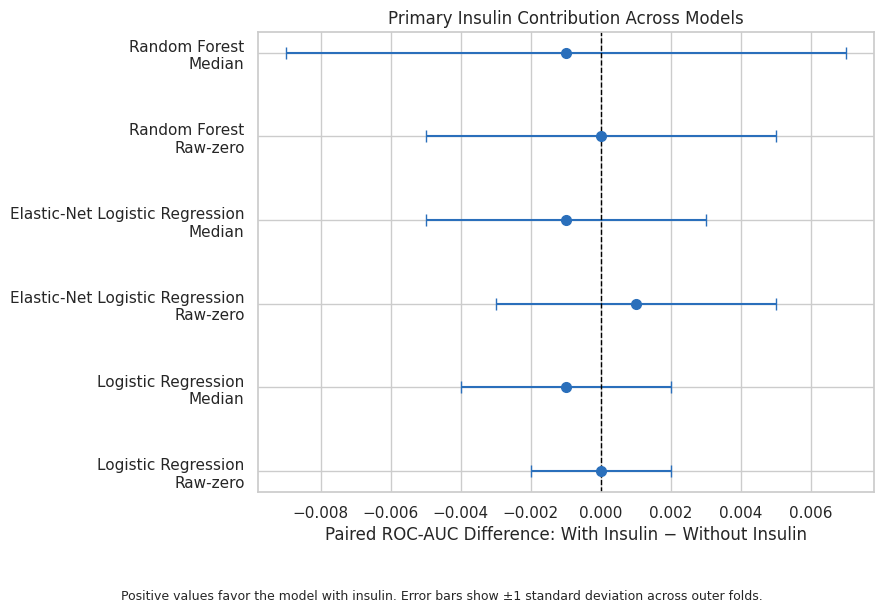

In [27]:
fig, ax = plt.subplots(figsize=(9, 6.2))

for position, (_, row) in enumerate(roc_ablation_plot_data.iterrows()):
    ax.errorbar(
        x=row["Mean Difference"],
        y=position,
        xerr=row["Standard Deviation"],
        fmt="o",
        color="#2a6fbb",
        capsize=4,
        markersize=7,
    )

ax.axvline(0, color="black", linewidth=1, linestyle="--")
ax.set_yticks(range(len(roc_ablation_plot_data)))
ax.set_yticklabels(roc_ablation_plot_data["Label"])
ax.set_xlabel("Paired ROC-AUC Difference: With Insulin − Without Insulin")
ax.set_title("Primary Insulin Contribution Across Models")

fig.text(
    0.5,
    0.015,
    "Positive values favor the model with insulin. "
    "Error bars show ±1 standard deviation across outer folds.",
    ha="center",
    va="bottom",
    fontsize=9,
)

plt.tight_layout(rect=[0, 0.08, 1, 1])
plt.savefig(
    FIGURES_DIR / "primary_roc_auc_ablation.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

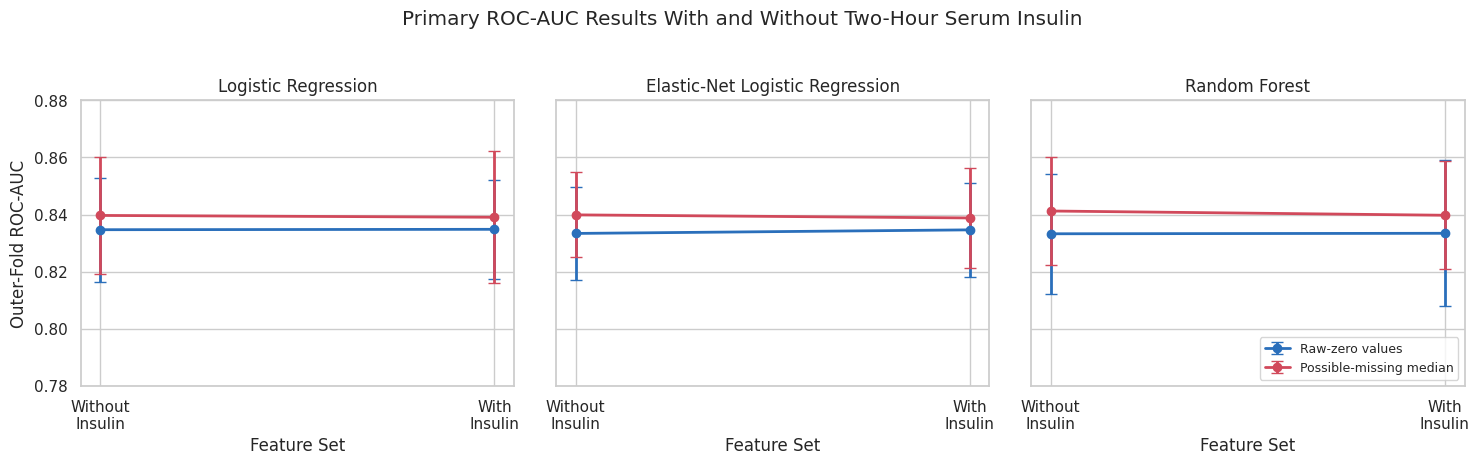

In [26]:
sns.set_theme(style="whitegrid", context="notebook")

fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 4.5),
    sharey=True,
)

line_styles = {
    "raw_zero": {
        "label": "Raw-zero values",
        "color": "#2a6fbb",
    },
    "possible_missing_median": {
        "label": "Possible-missing median",
        "color": "#d1495b",
    },
}

for ax, model_name in zip(axes, primary_models):
    model_data = primary_model_comparison_summary[
        primary_model_comparison_summary["Model"] == model_name
    ]

    for preprocessing, style in line_styles.items():
        subset = model_data[
            model_data["Preprocessing"] == preprocessing
        ].set_index("Feature Set")

        x_positions = [0, 1]
        feature_sets = ["Without Insulin", "With Insulin"]

        means = [
            subset.loc[feature_set, "ROC-AUC Mean"]
            for feature_set in feature_sets
        ]
        standard_deviations = [
            subset.loc[
                feature_set,
                "ROC-AUC Standard Deviation",
            ]
            for feature_set in feature_sets
        ]

        ax.errorbar(
            x_positions,
            means,
            yerr=standard_deviations,
            marker="o",
            linewidth=2,
            capsize=4,
            color=style["color"],
            label=style["label"],
        )

    ax.set_title(model_name)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Without\nInsulin", "With\nInsulin"])
    ax.set_ylim(0.78, 0.88)
    ax.set_xlabel("Feature Set")

axes[0].set_ylabel("Outer-Fold ROC-AUC")
axes[-1].legend(
    loc="lower right",
    fontsize=9,
)

fig.suptitle(
    "Primary ROC-AUC Results With and Without Two-Hour Serum Insulin",
    y=1.03,
)

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "primary_roc_auc_comparison.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

## 20. Out-of-Fold ROC and Precision-Recall Curves

The following figures use one held-out prediction per record from nested cross-validation. They visually compare the primary models under both preprocessing approaches, with and without two-hour serum insulin.

In [28]:
from sklearn.metrics import (
    precision_recall_curve,
    roc_curve,
)

primary_curve_conditions = [
    {
        "preprocessing_label": "Raw Zero Values",
        "feature_set": "Without Insulin",
        "label": "Raw-zero, without insulin",
        "color": "#2a6fbb",
        "linestyle": "-",
    },
    {
        "preprocessing_label": "Raw Zero Values",
        "feature_set": "With Insulin",
        "label": "Raw-zero, with insulin",
        "color": "#2a6fbb",
        "linestyle": "--",
    },
    {
        "preprocessing_label": "Possible Missing Median",
        "feature_set": "Without Insulin",
        "label": "Median, without insulin",
        "color": "#d1495b",
        "linestyle": "-",
    },
    {
        "preprocessing_label": "Possible Missing Median",
        "feature_set": "With Insulin",
        "label": "Median, with insulin",
        "color": "#d1495b",
        "linestyle": "--",
    },
]

def get_primary_oof_predictions(
    model_name,
    preprocessing_label,
    feature_set,
):
    experiment_name = (
        f"{model_name} | {preprocessing_label} | {feature_set}"
    )

    predictions = experiment_results[
        experiment_name
    ]["predictions"].sort_values("Row Index")

    return (
        predictions["Actual Outcome"].to_numpy(),
        predictions["Predicted Probability"].to_numpy(),
    )

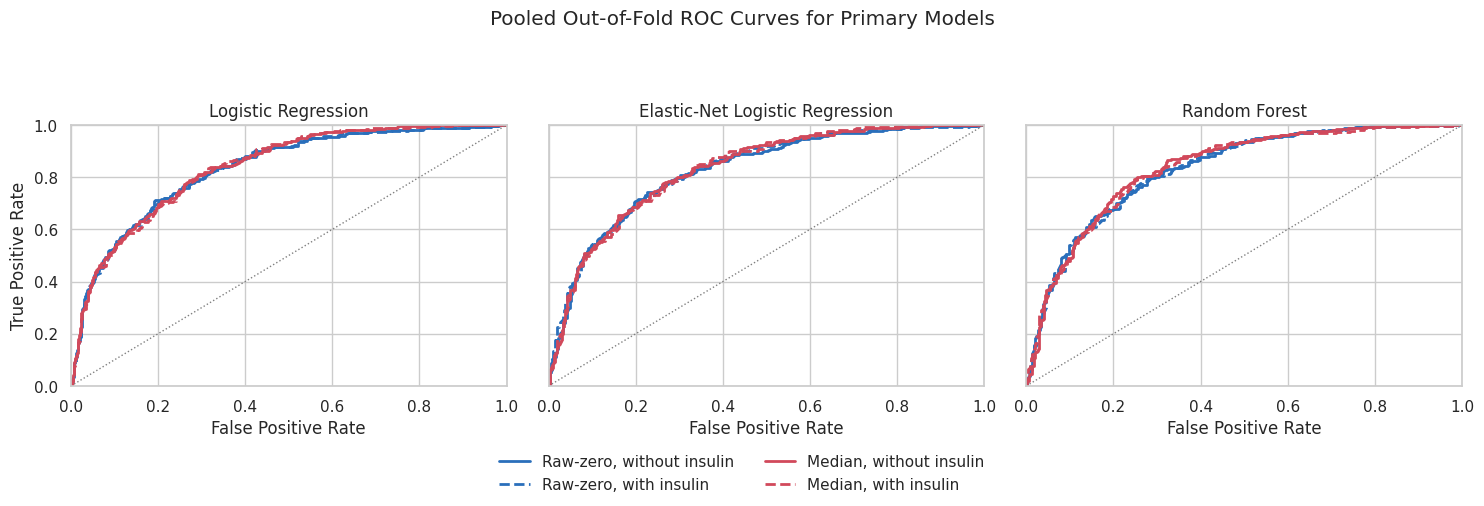

In [29]:
fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 4.8),
    sharex=True,
    sharey=True,
)

for ax, model_name in zip(axes, primary_models):
    for condition in primary_curve_conditions:
        y_true, predicted_probabilities = get_primary_oof_predictions(
            model_name,
            condition["preprocessing_label"],
            condition["feature_set"],
        )

        false_positive_rate, true_positive_rate, _ = roc_curve(
            y_true,
            predicted_probabilities,
        )

        ax.plot(
            false_positive_rate,
            true_positive_rate,
            color=condition["color"],
            linestyle=condition["linestyle"],
            linewidth=2,
            label=condition["label"],
        )

    ax.plot(
        [0, 1],
        [0, 1],
        color="gray",
        linestyle=":",
        linewidth=1,
    )
    ax.set_title(model_name)
    ax.set_xlabel("False Positive Rate")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)

axes[0].set_ylabel("True Positive Rate")

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=2,
    frameon=False,
)
fig.suptitle(
    "Pooled Out-of-Fold ROC Curves for Primary Models",
    y=1.03,
)

plt.tight_layout(rect=[0, 0.10, 1, 0.95])
plt.savefig(
    FIGURES_DIR / "primary_roc_curves.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

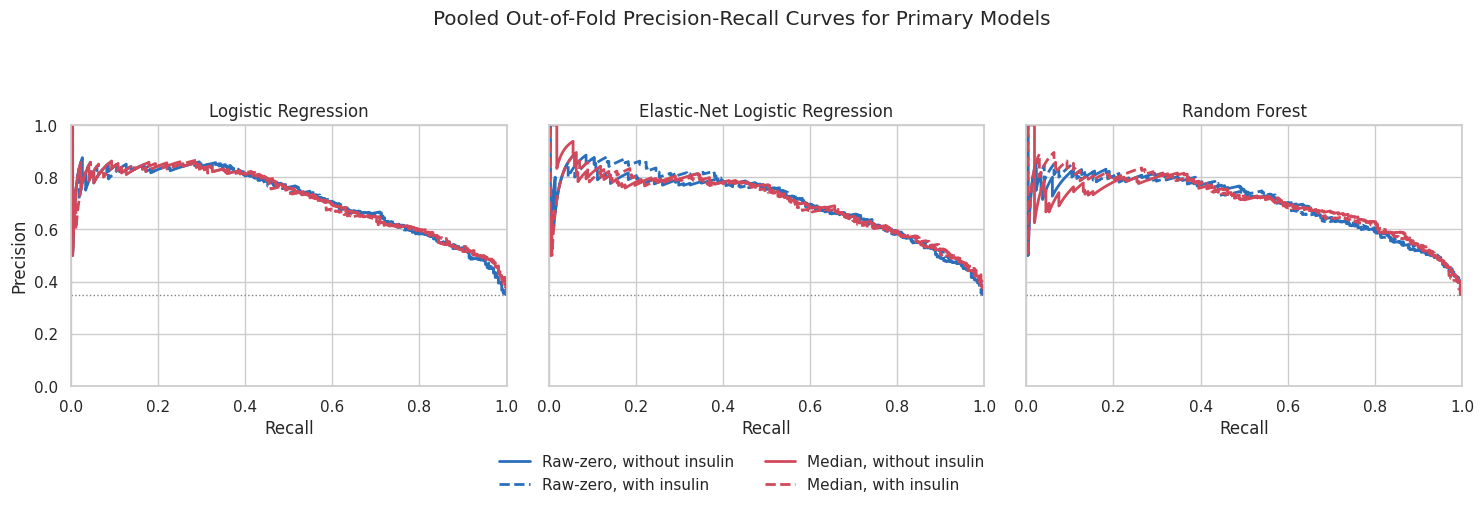

In [30]:
outcome_prevalence = y.mean()

fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 4.8),
    sharex=True,
    sharey=True,
)

for ax, model_name in zip(axes, primary_models):
    for condition in primary_curve_conditions:
        y_true, predicted_probabilities = get_primary_oof_predictions(
            model_name,
            condition["preprocessing_label"],
            condition["feature_set"],
        )

        precision, recall, _ = precision_recall_curve(
            y_true,
            predicted_probabilities,
        )

        ax.plot(
            recall,
            precision,
            color=condition["color"],
            linestyle=condition["linestyle"],
            linewidth=2,
            label=condition["label"],
        )

    ax.axhline(
        outcome_prevalence,
        color="gray",
        linestyle=":",
        linewidth=1,
    )
    ax.set_title(model_name)
    ax.set_xlabel("Recall")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)

axes[0].set_ylabel("Precision")

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=2,
    frameon=False,
)
fig.suptitle(
    "Pooled Out-of-Fold Precision-Recall Curves for Primary Models",
    y=1.03,
)

plt.tight_layout(rect=[0, 0.10, 1, 0.95])
plt.savefig(
    FIGURES_DIR / "primary_precision_recall_curves.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

## 21. Out-of-Fold Calibration Curves

These reliability diagrams compare predicted probabilities with observed outcome frequencies. Curves closer to the diagonal line are better calibrated.

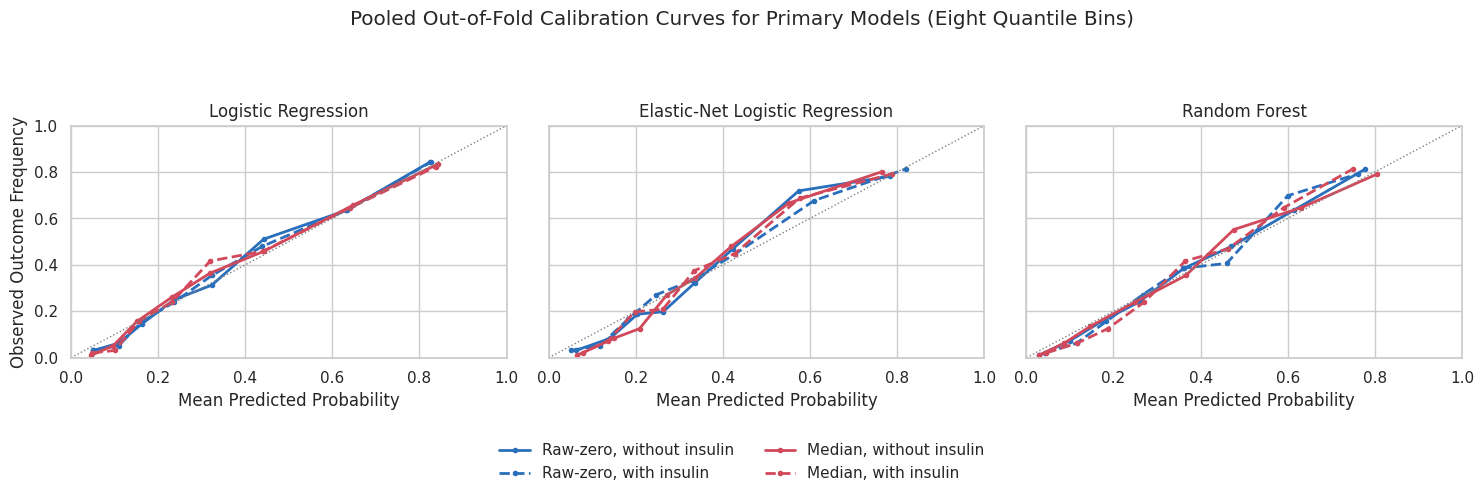

In [32]:
from sklearn.calibration import calibration_curve

fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 4.8),
    sharex=True,
    sharey=True,
)

for ax, model_name in zip(axes, primary_models):
    for condition in primary_curve_conditions:
        y_true, predicted_probabilities = get_primary_oof_predictions(
            model_name,
            condition["preprocessing_label"],
            condition["feature_set"],
        )

        observed_frequency, mean_predicted_probability = calibration_curve(
            y_true,
            predicted_probabilities,
            n_bins=8,
            strategy="quantile",
        )

        ax.plot(
            mean_predicted_probability,
            observed_frequency,
            color=condition["color"],
            linestyle=condition["linestyle"],
            marker="o",
            markersize=3,
            linewidth=2,
            label=condition["label"],
        )

    ax.plot(
        [0, 1],
        [0, 1],
        color="gray",
        linestyle=":",
        linewidth=1,
    )
    ax.set_title(model_name)
    ax.set_xlabel("Mean Predicted Probability")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)

axes[0].set_ylabel("Observed Outcome Frequency")

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.02),
    ncol=2,
    frameon=False,
)

fig.suptitle(
    "Pooled Out-of-Fold Calibration Curves for Primary Models "
    "(Eight Quantile Bins)",
    y=1.03,
)

plt.tight_layout(rect=[0, 0.16, 1, 0.95])
plt.savefig(
    FIGURES_DIR / "primary_calibration_curves.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

## 22. Held-Out Permutation Importance

Permutation importance measures the decrease in held-out ROC-AUC after a feature is shuffled. A larger positive decrease suggests that the feature contributed more to predictive performance. Because predictors may be correlated, importance values should not be interpreted as causal effects.

In [33]:
from sklearn.inspection import permutation_importance

def run_nested_permutation_importance(
    model_name,
    feature_names,
    feature_set_name,
    preprocessing_approach,
    n_repeats=20,
):
    config = MODEL_CONFIGURATIONS[model_name]

    importance_rows = []
    parameter_rows = []

    for outer_fold, (train_indices, test_indices) in enumerate(
        outer_cv.split(X, y),
        start=1,
    ):
        print(
            f"Running {model_name} permutation importance | "
            f"outer fold {outer_fold}/{OUTER_SPLITS}",
            flush=True,
        )

        X_train = X.loc[train_indices, feature_names].copy()
        X_test = X.loc[test_indices, feature_names].copy()
        y_train = y.iloc[train_indices].copy()
        y_test = y.iloc[test_indices].copy()

        inner_cv = StratifiedKFold(
            n_splits=INNER_SPLITS,
            shuffle=True,
            random_state=RANDOM_STATE + outer_fold,
        )

        pipeline = Pipeline(
            steps=[
                (
                    "preprocessor",
                    make_preprocessor(
                        feature_names,
                        preprocessing_approach,
                    ),
                ),
                ("model", clone(config["estimator"])),
            ]
        )

        grid_search = GridSearchCV(
            estimator=pipeline,
            param_grid=config["param_grid"],
            scoring="roc_auc",
            cv=inner_cv,
            n_jobs=-1,
            refit=True,
            return_train_score=False,
            error_score="raise",
        )

        grid_search.fit(X_train, y_train)

        best_estimator = grid_search.best_estimator_
        baseline_probabilities = best_estimator.predict_proba(X_test)[:, 1]
        baseline_roc_auc = roc_auc_score(
            y_test,
            baseline_probabilities,
        )

        importance = permutation_importance(
            estimator=best_estimator,
            X=X_test,
            y=y_test,
            scoring="roc_auc",
            n_repeats=n_repeats,
            random_state=RANDOM_STATE + (100 * outer_fold),
            n_jobs=-1,
        )

        for feature_name, mean_drop, standard_deviation in zip(
            feature_names,
            importance.importances_mean,
            importance.importances_std,
        ):
            importance_rows.append(
                {
                    "Model": model_name,
                    "Preprocessing": preprocessing_approach,
                    "Feature Set": feature_set_name,
                    "Outer Fold": outer_fold,
                    "Feature": feature_name,
                    "Baseline Test ROC-AUC": baseline_roc_auc,
                    "Mean ROC-AUC Decrease": mean_drop,
                    "Permutation Standard Deviation": standard_deviation,
                }
            )

        parameter_rows.append(
            {
                "Model": model_name,
                "Preprocessing": preprocessing_approach,
                "Feature Set": feature_set_name,
                "Outer Fold": outer_fold,
                "Best Inner ROC-AUC": grid_search.best_score_,
                "Selected Parameters": json.dumps(
                    grid_search.best_params_
                ),
            }
        )

    return (
        pd.DataFrame(importance_rows),
        pd.DataFrame(parameter_rows),
    )

In [34]:
importance_conditions = [
    {
        "model_name": "Logistic Regression",
        "feature_names": ALL_PREDICTORS,
        "feature_set_name": "With Insulin",
        "preprocessing_approach": "possible_missing_median",
    },
    {
        "model_name": "Random Forest",
        "feature_names": ALL_PREDICTORS,
        "feature_set_name": "With Insulin",
        "preprocessing_approach": "possible_missing_median",
    },
]

importance_frames = []
importance_parameter_frames = []

for condition in importance_conditions:
    importance_by_fold, importance_parameters = (
        run_nested_permutation_importance(
            model_name=condition["model_name"],
            feature_names=condition["feature_names"],
            feature_set_name=condition["feature_set_name"],
            preprocessing_approach=condition[
                "preprocessing_approach"
            ],
        )
    )

    importance_frames.append(importance_by_fold)
    importance_parameter_frames.append(importance_parameters)

held_out_permutation_importance_by_fold = pd.concat(
    importance_frames,
    ignore_index=True,
)
held_out_permutation_importance_parameters = pd.concat(
    importance_parameter_frames,
    ignore_index=True,
)

held_out_permutation_importance_summary = (
    held_out_permutation_importance_by_fold
    .groupby(
        ["Model", "Preprocessing", "Feature Set", "Feature"],
        as_index=False,
    )
    .agg(
        mean_roc_auc_decrease=(
            "Mean ROC-AUC Decrease",
            "mean",
        ),
        standard_deviation=(
            "Mean ROC-AUC Decrease",
            "std",
        ),
    )
    .rename(
        columns={
            "mean_roc_auc_decrease": "Mean ROC-AUC Decrease",
            "standard_deviation": "Outer-Fold Standard Deviation",
        }
    )
    .sort_values(
        ["Model", "Mean ROC-AUC Decrease"],
        ascending=[True, False],
    )
)

held_out_permutation_importance_by_fold.to_csv(
    TABLES_DIR / "held_out_permutation_importance_by_fold.csv",
    index=False,
)
held_out_permutation_importance_summary.to_csv(
    TABLES_DIR / "held_out_permutation_importance_summary.csv",
    index=False,
)
held_out_permutation_importance_parameters.to_csv(
    TABLES_DIR / "held_out_permutation_importance_parameters.csv",
    index=False,
)

display(held_out_permutation_importance_summary.round(3))

Running Logistic Regression permutation importance | outer fold 1/5
Running Logistic Regression permutation importance | outer fold 2/5
Running Logistic Regression permutation importance | outer fold 3/5
Running Logistic Regression permutation importance | outer fold 4/5
Running Logistic Regression permutation importance | outer fold 5/5
Running Random Forest permutation importance | outer fold 1/5
Running Random Forest permutation importance | outer fold 2/5
Running Random Forest permutation importance | outer fold 3/5
Running Random Forest permutation importance | outer fold 4/5
Running Random Forest permutation importance | outer fold 5/5


,Model,Preprocessing,Feature Set,Feature,Mean ROC-AUC Decrease,Outer-Fold Standard Deviation
4,Logistic Regression,possible_missing_median,With Insulin,Glucose,0.183,0.016
1,Logistic Regression,possible_missing_median,With Insulin,BMI,0.051,0.019
6,Logistic Regression,possible_missing_median,With Insulin,Pregnancies,0.020,0.010
3,Logistic Regression,possible_missing_median,With Insulin,DiabetesPedigreeFunction,0.016,0.005
0,Logistic Regression,possible_missing_median,With Insulin,Age,0.004,0.003
5,Logistic Regression,possible_missing_median,With Insulin,Insulin,0.003,0.004
2,Logistic Regression,possible_missing_median,With Insulin,BloodPressure,0.003,0.005
7,Logistic Regression,possible_missing_median,With Insulin,SkinThickness,-0.002,0.003
12,Random Forest,possible_missing_median,With Insulin,Glucose,0.140,0.022
9,Random Forest,possible_missing_median,With Insulin,BMI,0.041,0.011


## 23. Held-Out Permutation-Importance Visualization

This figure summarizes the held-out permutation importance results. Larger positive values indicate a larger decrease in ROC-AUC when a feature is shuffled.

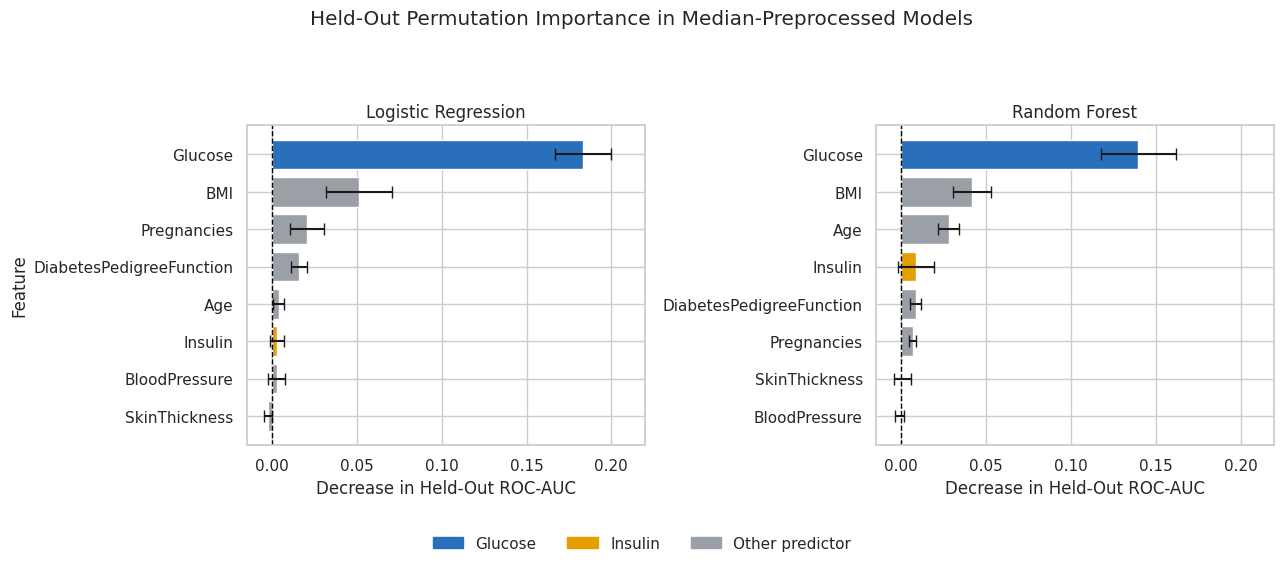

In [35]:
from matplotlib.patches import Patch

importance_models = [
    "Logistic Regression",
    "Random Forest",
]

x_min = min(
    -0.01,
    (
        held_out_permutation_importance_summary[
            "Mean ROC-AUC Decrease"
        ]
        - held_out_permutation_importance_summary[
            "Outer-Fold Standard Deviation"
        ]
    ).min()
    - 0.01,
)

x_max = (
    held_out_permutation_importance_summary[
        "Mean ROC-AUC Decrease"
    ]
    + held_out_permutation_importance_summary[
        "Outer-Fold Standard Deviation"
    ]
).max() + 0.02

fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 5.5),
    sharex=True,
)

for ax, model_name in zip(axes, importance_models):
    plot_data = (
        held_out_permutation_importance_summary[
            held_out_permutation_importance_summary["Model"]
            == model_name
        ]
        .sort_values("Mean ROC-AUC Decrease", ascending=True)
        .copy()
    )

    bar_colors = [
        "#2a6fbb" if feature == "Glucose"
        else "#e69f00" if feature == "Insulin"
        else "#9aa0a6"
        for feature in plot_data["Feature"]
    ]

    ax.barh(
        plot_data["Feature"],
        plot_data["Mean ROC-AUC Decrease"],
        xerr=plot_data["Outer-Fold Standard Deviation"],
        color=bar_colors,
        capsize=4,
    )

    ax.axvline(0, color="black", linewidth=1, linestyle="--")
    ax.set_title(model_name)
    ax.set_xlim(x_min, x_max)
    ax.set_xlabel("Decrease in Held-Out ROC-AUC")

axes[0].set_ylabel("Feature")

legend_handles = [
    Patch(color="#2a6fbb", label="Glucose"),
    Patch(color="#e69f00", label="Insulin"),
    Patch(color="#9aa0a6", label="Other predictor"),
]

fig.legend(
    handles=legend_handles,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.01),
    ncol=3,
    frameon=False,
)

fig.suptitle(
    "Held-Out Permutation Importance in Median-Preprocessed Models",
    y=1.02,
)

plt.tight_layout(rect=[0, 0.10, 1, 0.95])
plt.savefig(
    FIGURES_DIR / "held_out_permutation_importance.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

## 24. Glucose-Excluded Sensitivity Visualization

This figure summarizes the secondary analysis in which glucose was excluded from every feature set. It shows whether the contribution of two-hour serum insulin changes when the strongest predictor is unavailable.

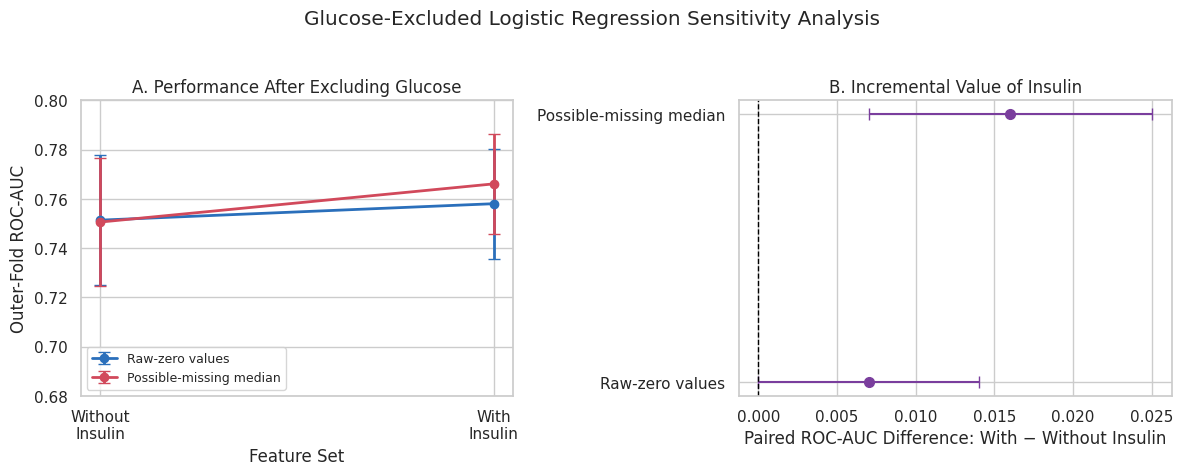

In [36]:
glucose_sensitivity_styles = {
    "raw_zero": {
        "label": "Raw-zero values",
        "color": "#2a6fbb",
    },
    "possible_missing_median": {
        "label": "Possible-missing median",
        "color": "#d1495b",
    },
}

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 4.6),
)

# Panel A: ROC-AUC with glucose excluded
for preprocessing, style in glucose_sensitivity_styles.items():
    subset = glucose_excluded_logistic_summary[
        glucose_excluded_logistic_summary["Preprocessing"]
        == preprocessing
    ].set_index("Feature Set")

    feature_sets = ["Without Insulin", "With Insulin"]
    means = [
        subset.loc[feature_set, "ROC-AUC Mean"]
        for feature_set in feature_sets
    ]
    standard_deviations = [
        subset.loc[
            feature_set,
            "ROC-AUC Standard Deviation",
        ]
        for feature_set in feature_sets
    ]

    axes[0].errorbar(
        [0, 1],
        means,
        yerr=standard_deviations,
        marker="o",
        linewidth=2,
        capsize=4,
        color=style["color"],
        label=style["label"],
    )

axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(
    ["Without\nInsulin", "With\nInsulin"]
)
axes[0].set_ylim(0.68, 0.80)
axes[0].set_xlabel("Feature Set")
axes[0].set_ylabel("Outer-Fold ROC-AUC")
axes[0].set_title("A. Performance After Excluding Glucose")
axes[0].legend(fontsize=9)

# Panel B: paired insulin contribution
glucose_roc_difference_data = glucose_excluded_ablation_summary[
    glucose_excluded_ablation_summary["Metric Difference"]
    == "ROC-AUC Difference (With - Without)"
].copy()

glucose_roc_difference_data["Label"] = (
    glucose_roc_difference_data["Preprocessing"].replace(
        {
            "raw_zero": "Raw-zero values",
            "possible_missing_median": "Possible-missing median",
        }
    )
)

for position, (_, row) in enumerate(
    glucose_roc_difference_data.iterrows()
):
    axes[1].errorbar(
        row["Mean Difference"],
        position,
        xerr=row["Standard Deviation"],
        fmt="o",
        color="#7a3e9d",
        capsize=4,
        markersize=7,
    )

axes[1].axvline(
    0,
    color="black",
    linewidth=1,
    linestyle="--",
)
axes[1].set_yticks(range(len(glucose_roc_difference_data)))
axes[1].set_yticklabels(glucose_roc_difference_data["Label"])
axes[1].set_xlabel(
    "Paired ROC-AUC Difference: With − Without Insulin"
)
axes[1].set_title("B. Incremental Value of Insulin")

fig.suptitle(
    "Glucose-Excluded Logistic Regression Sensitivity Analysis",
    y=1.03,
)

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "glucose_excluded_sensitivity.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()